Hexagon FBQC fusion network: geometry, checks, logicals, and thresholds

A three-colour hexagonal fusion network on a triangular lattice: red, green and
blue hexagons, one of each per unit tile, periodically tiled. Companion to
`sixring_fbqc_walkthrough.ipynb` -- same approach, geometry first, qubits and
circuits layered on afterward.

| § | what happens |
|---|---|
| 1 | Geometry: points, hexagons, tiles, edge colouring, periodic boundary conditions |
| 2 | The circuit: qubits in space and time, cluster-state CZs, the 6-step fusion schedule |
| 3 | Detectors: the hexagon check operators, derived and verified against Stim |
| 4 | Logicals: the 6 logical operators, found by brute-force nullspace search |
| 5 | Closed-form logicals: the same 6 logicals, hand-derived and verified (`has_flow`) |
| 6 | Measurement-error threshold: `p_meas` sweep decoded with `pymatching`, threshold ≈ 1.0% |
| 7 | Heralded erasure: pure `p_erase` sweep with per-shot reweighted MWPM, threshold ≈ 12-14% |

In [1]:
import numpy as np
import stim
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from collections import Counter, defaultdict

print("stim", stim.__version__)

stim 1.16.0


---
## 1. Geometry

Points live on a triangular lattice indexed by integer axial coordinates
`(i, j)`. Every point has 6 nearest neighbours, offset by the six axial
directions `HEX_DIRS`. A **hexagon** centred at point `c` is the 6 points
`c + dir` for each of those directions, listed in a fixed cyclic order so that
consecutive entries are the hexagon's edges.

One **tile** groups three hexagons — red, green, blue — by centre offset from
a tile origin `(0, 0)`:

| colour | centre offset |
|---|---|
| red   | (0, -1) |
| green | (1, 0)  |
| blue  | (-1, 1) |

Tiles repeat on a square grid with translation vectors `(3, 0)` and `(0, 3)`.
Given `x_max, y_max` tiles, the lattice is periodic with period
`(3*x_max, 3*y_max)`.

Every edge of the tiling borders exactly two hexagons of two different
colours; the edge's own colour is the **third**, missing colour — a red edge
is bordered by blue and green, a blue edge by green and red, a green edge by
red and blue. Not every lattice site is used: one third of the sites (those
with `(i - j) % 3 == 1`, given this offset choice) are neither a hexagon
centre nor a vertex.

In [2]:
# The six axial nearest-neighbour directions, in cyclic (hexagon-boundary) order.
HEX_DIRS = [(1, -1), (1, 0), (0, 1), (-1, 1), (-1, 0), (0, -1)]

# Hexagon centres within one tile, relative to the tile origin (0, 0).
TILE_OFFSETS = {"red": (0, -1), "green": (1, 0), "blue": (-1, 1)}

TILE_VECS = [(3, 0), (0, 3)]  # tile-to-tile translation


class HexLattice:
    """Periodic tiling of the triangular lattice by red/green/blue hexagons.

    `x_max`, `y_max` tiles in each direction, wrapping periodically with
    period (3*x_max, 3*y_max).
    """

    def __init__(self, x_max, y_max):
        self.x_max, self.y_max = x_max, y_max
        self.Lx, self.Ly = 3 * x_max, 3 * y_max

        # hexagons[(colour, centre)] = the 6 vertices, in cyclic order
        self.hexagons = {}
        for a in range(x_max):
            for b in range(y_max):
                tx, ty = 3 * a, 3 * b
                for colour, (dx, dy) in TILE_OFFSETS.items():
                    c = self.wrap((tx + dx, ty + dy))
                    verts = [self.wrap((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                    self.hexagons[(colour, c)] = verts

        self.points = sorted(set(p for verts in self.hexagons.values() for p in verts))

        # every boundary edge -> the set of hexagon colours it borders
        edge_touch = defaultdict(set)
        for (colour, c), verts in self.hexagons.items():
            for k in range(6):
                p, q = verts[k], verts[(k + 1) % 6]
                edge_touch[frozenset((p, q))].add(colour)
        self.edge_touch = edge_touch

        # each edge borders exactly 2 colours; it is coloured by the 3rd
        all_colours = set(TILE_OFFSETS)
        self.edge_colour = {edge: (all_colours - cols).pop()
                             for edge, cols in edge_touch.items()}

    def wrap(self, p):
        return (p[0] % self.Lx, p[1] % self.Ly)

    def colour_of_edge(self, p, q):
        """Colour of the edge between two (adjacent) points, wrapped periodically."""
        return self.edge_colour[frozenset((self.wrap(p), self.wrap(q)))]


net = HexLattice(4, 4)
print(f"tiles = {net.x_max * net.y_max}, hexagons = {len(net.hexagons)}, points = {len(net.points)}")

tiles = 16, hexagons = 48, points = 96


### Sanity checks

Every edge should border **exactly 2** hexagons of **2 different** colours
(never 1, never 3), and the three colour pairs (red-green, green-blue,
blue-red) should occur equally often — otherwise some colour is over- or
under-represented and the tiling isn't self-consistent.

In [3]:
touch_dist = Counter(len(cols) for cols in net.edge_touch.values())
print("edge colour-touch-count distribution:", dict(touch_dist))
assert touch_dist.keys() == {2}, "every edge should border exactly 2 hexagon colours"

pair_dist = Counter(frozenset(cols) for cols in net.edge_touch.values())
print("colour-pair distribution:", {tuple(sorted(k)): v for k, v in pair_dist.items()})
assert len(set(pair_dist.values())) == 1, "colour pairs should occur equally often"

print("every hexagon has 6 distinct vertices:",
      all(len(set(v)) == 6 for v in net.hexagons.values()))

# every point should touch exactly one edge of each colour (needed for the
# circuit's single-colour fusion steps to consume every qubit exactly once)
point_colour_degree = defaultdict(Counter)
for edge, colour in net.edge_colour.items():
    p, r = tuple(edge)
    point_colour_degree[p][colour] += 1
    point_colour_degree[r][colour] += 1
degree_profiles = Counter(tuple(sorted(point_colour_degree[p].items())) for p in net.points)
print("point colour-degree profiles:", dict(degree_profiles))
assert set(degree_profiles) == {(("blue", 1), ("green", 1), ("red", 1))}, \
    "every point should have exactly one red, one green, one blue edge"

# spot-check against the confirmed hand-derived hexagons
print()
print("red @ (0,-1):  ", net.hexagons[("red", net.wrap((0, -1)))])
print("green @ (1,0): ", net.hexagons[("green", net.wrap((1, 0)))])
print("blue @ (-1,1): ", net.hexagons[("blue", net.wrap((-1, 1)))])
print()
print("colour of edge (0,0)-(1,-1):", net.colour_of_edge((0, 0), (1, -1)))
print("colour of edge (0,0)-(0,1): ", net.colour_of_edge((0, 0), (0, 1)))

edge colour-touch-count distribution: {2: 144}
colour-pair distribution: {('blue', 'red'): 48, ('green', 'red'): 48, ('blue', 'green'): 48}
every hexagon has 6 distinct vertices: True
point colour-degree profiles: {(('blue', 1), ('green', 1), ('red', 1)): 96}

red @ (0,-1):   [(1, 10), (1, 11), (0, 0), (11, 0), (11, 11), (0, 10)]
green @ (1,0):  [(2, 11), (2, 0), (1, 1), (0, 1), (0, 0), (1, 11)]
blue @ (-1,1):  [(0, 0), (0, 1), (11, 2), (10, 2), (10, 1), (11, 0)]

colour of edge (0,0)-(1,-1): blue
colour of edge (0,0)-(0,1):  red


### Visualise

Axial coordinates `(i, j)` map to the plane as `x = i + j/2`, `y = j * sqrt(3)/2`
— under this map the six `HEX_DIRS` become unit vectors spaced 60° apart, so
each hexagon renders as a regular hexagon. A quick plot of a small periodic
patch is the fastest way to confirm the tiling looks right before adding
qubits on top of it.

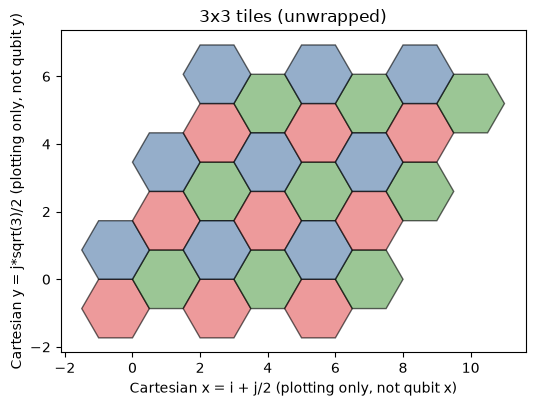

In [4]:
def to_xy(p):
    """Cartesian embedding for plotting only -- NOT the qubit (x, y) label.
    Qubits are always addressed by their axial (i, j) pair (net.points,
    Spacetime.q(x, y, t)); this is only used to lay hexagons out on a plot."""
    i, j = p
    return (i + 0.5 * j, (np.sqrt(3) / 2) * j)


COLOURS = {"red": "#e15759", "green": "#59a14f", "blue": "#4e79a7"}


def plot_patch(x_max, y_max, ax=None):
    """Plot an unwrapped x_max x y_max patch of tiles (no periodic wrap,
    so hexagons near the edge render as ordinary finite hexagons)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    for a in range(x_max):
        for b in range(y_max):
            tx, ty = 3 * a, 3 * b
            for colour, (dx, dy) in TILE_OFFSETS.items():
                c = (tx + dx, ty + dy)
                verts = [to_xy((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                ax.add_patch(Polygon(verts, closed=True, facecolor=COLOURS[colour],
                                      edgecolor="black", linewidth=1, alpha=0.6))
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xlabel("Cartesian x = i + j/2 (plotting only, not qubit x)")
    ax.set_ylabel("Cartesian y = j*sqrt(3)/2 (plotting only, not qubit y)")
    ax.set_title(f"{x_max}x{y_max} tiles (unwrapped)")
    return ax


plot_patch(3, 3)
plt.show()

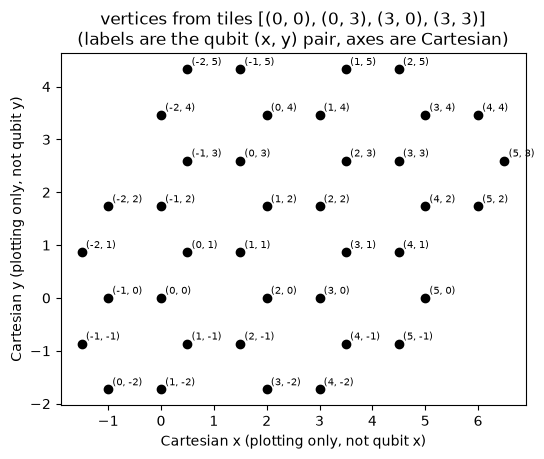

39 distinct vertices


In [5]:
tiles = [(0, 0), (0, 3), (3, 0), (3, 3)]

verts = set()
for (tx, ty) in tiles:
    for colour, (dx, dy) in TILE_OFFSETS.items():
        c = (tx + dx, ty + dy)
        for ox, oy in HEX_DIRS:
            verts.add((c[0] + ox, c[1] + oy))
verts = sorted(verts)

xs, ys = zip(*(to_xy(p) for p in verts))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xs, ys, color="black", zorder=2)
for p, x, y in zip(verts, xs, ys):
    ax.annotate(str(p), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_aspect("equal")
ax.set_xlabel("Cartesian x (plotting only, not qubit x)")
ax.set_ylabel("Cartesian y (plotting only, not qubit y)")
ax.set_title(f"vertices from tiles {tiles}\n(labels are the qubit (x, y) pair, axes are Cartesian)")
plt.show()

print(f"{len(verts)} distinct vertices")

### Check the periodic boundary conditions

Tiles `(0,0), (3,0), (0,3), (3,3)` are exactly the 4 tiles of `HexLattice(2, 2)`
(period `(6, 6)`) — the smallest lattice that still contains all of them, so
wrapping is forced to actually do something. Plot the wrapped points (black),
the fundamental-cell boundary (red), and a few periodic images (grey, shifted
by whole periods) — if PBC is implemented correctly the grey copies should
tile seamlessly against the black cell with no gaps or collisions.

period = (6, 6), wrapped distinct points = 24  (unwrapped was 39)


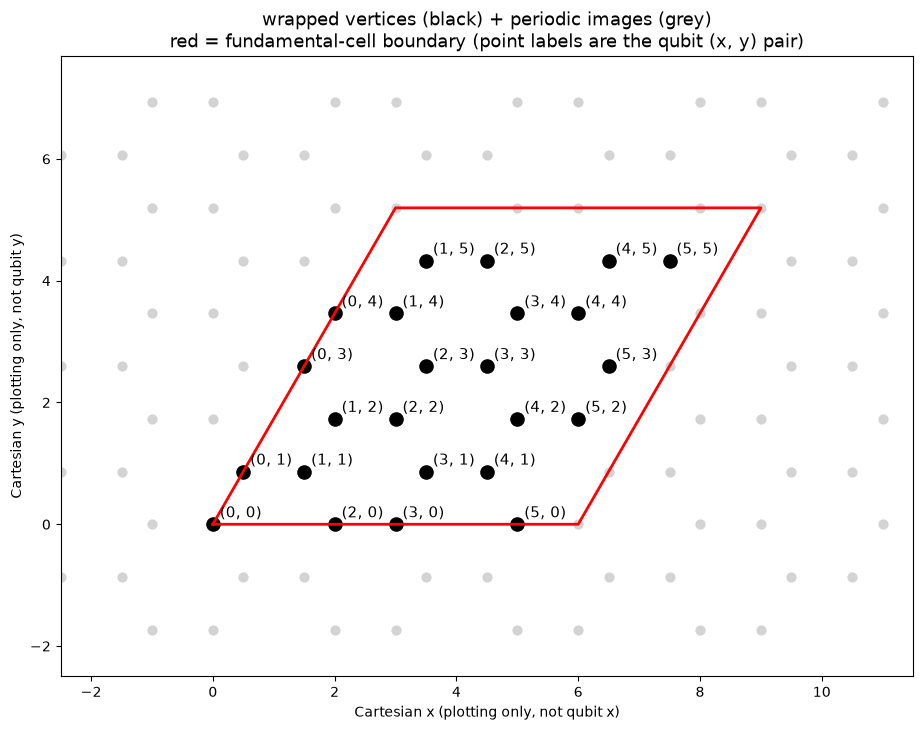

In [6]:
net_small = HexLattice(2, 2)  # tiles (0,0),(3,0),(0,3),(3,3); period (6,6)
print(f"period = ({net_small.Lx}, {net_small.Ly}), wrapped distinct points = {len(net_small.points)}"
      f"  (unwrapped was {len(verts)})")

Tx = to_xy((net_small.Lx, 0))
Ty = to_xy((0, net_small.Ly))
base_xy = [to_xy(p) for p in net_small.points]

fig, ax = plt.subplots(figsize=(11, 11))
for sa in (-1, 0, 1):
    for sb in (-1, 0, 1):
        is_origin = (sa, sb) == (0, 0)
        shifted = [(x + sa * Tx[0] + sb * Ty[0], y + sa * Tx[1] + sb * Ty[1]) for x, y in base_xy]
        xs, ys = zip(*shifted)
        ax.scatter(xs, ys, color="black" if is_origin else "lightgray",
                   s=90 if is_origin else 40, zorder=2 if is_origin else 1)

corners = [(0, 0), Tx, (Tx[0] + Ty[0], Tx[1] + Ty[1]), Ty, (0, 0)]
ax.plot(*zip(*corners), color="red", linewidth=2)

for p, (x, y) in zip(net_small.points, base_xy):
    ax.annotate(str(p), (x, y), fontsize=11, xytext=(5, 5), textcoords="offset points")

ax.set_aspect("equal")
margin = 2.5
xs_cell, ys_cell = zip(*corners)
ax.set_xlim(min(xs_cell) - margin, max(xs_cell) + margin)
ax.set_ylim(min(ys_cell) - margin, max(ys_cell) + margin)
ax.set_xlabel("Cartesian x (plotting only, not qubit x)")
ax.set_ylabel("Cartesian y (plotting only, not qubit y)")
ax.set_title("wrapped vertices (black) + periodic images (grey)\nred = fundamental-cell boundary "
             "(point labels are the qubit (x, y) pair)", fontsize=13)
plt.show()

### Raw-coordinate plot

Unlike the hexagon-shaped plots above, this one places each point at its own
`(x, y)` axial coordinate directly — no Cartesian rescaling — so it's a
literal picture of what `Spacetime.q(x, y, t)` addresses. Useful for reading
off which points share an `x` or `y` value, tracing edge-colour patterns, etc.
Edges that wrap across the periodic boundary are marked with a square at each
endpoint instead of a connecting line (drawing the line would cut across the
whole plot).

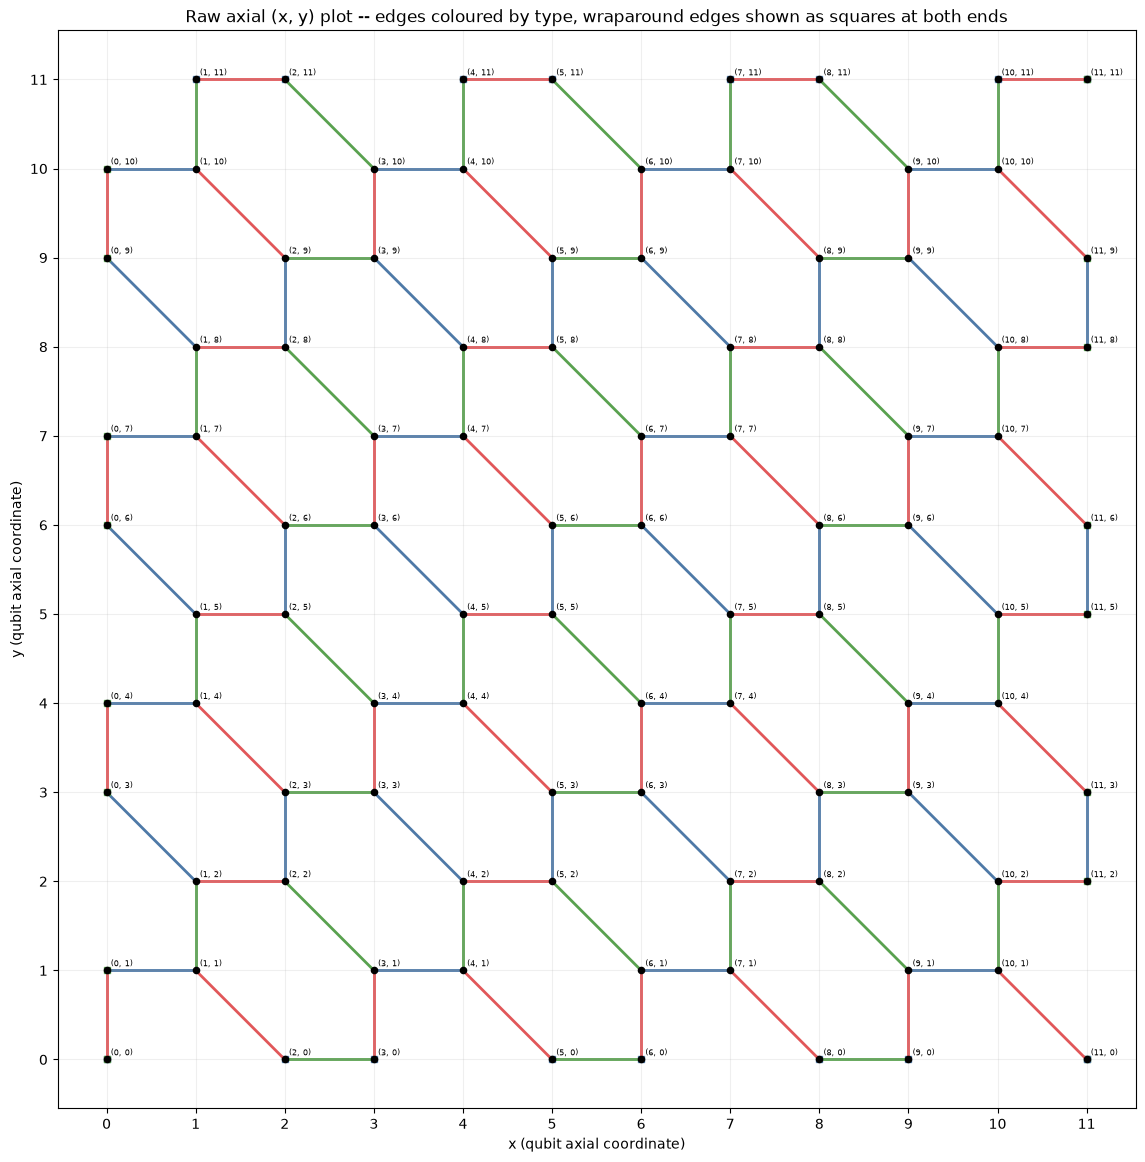

In [7]:
def plot_raw(net, ax=None, figsize=(14, 14)):
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        di, dj = r[0] - p[0], r[1] - p[1]
        if (di, dj) in HEX_DIRS or (-di, -dj) in HEX_DIRS:
            ax.plot([p[0], r[0]], [p[1], r[1]], color=COLOURS[colour], linewidth=2, zorder=1)
        else:
            # wraps across the periodic boundary -- mark both ends instead of
            # drawing a line straight across the plot
            ax.plot(*p, marker="s", color=COLOURS[colour], markersize=5, zorder=1)
            ax.plot(*r, marker="s", color=COLOURS[colour], markersize=5, zorder=1)

    xs, ys = zip(*net.points)
    ax.scatter(xs, ys, color="black", s=20, zorder=2)
    for p in net.points:
        ax.annotate(f"{p}", p, fontsize=6, xytext=(3, 3), textcoords="offset points", zorder=3)

    ax.set_xlabel("x (qubit axial coordinate)")
    ax.set_ylabel("y (qubit axial coordinate)")
    ax.set_xticks(range(net.Lx))
    ax.set_yticks(range(net.Ly))
    ax.grid(alpha=0.2)
    ax.set_aspect("equal")
    ax.set_title("Raw axial (x, y) plot -- edges coloured by type, "
                 "wraparound edges shown as squares at both ends")
    return ax


plot_raw(net)
plt.show()

---
## 2. The circuit

Every spatial point `(x, y)` gets its own qubit at every timestep `t`, for
`total_t = 6 * n_cycles` timesteps, wrapping periodically in time just like
space: qubit `(x, y, total_t)` is qubit `(x, y, 0)`. So there are
`len(net.points) * total_t` qubits in total.

Every qubit starts in `|+>`. Two qubits get a `CZ` if they're the **same
vertex at adjacent (periodic) timesteps** — this is what links a vertex's
qubit at time `t` to its replacement at `t+1`.

Each *cycle* is 6 timesteps, and at each timestep exactly one colour's worth
of spatial edges gets fused (the fusion primitive — `CNOT a b; H a; M a b` —
is the same destructive Bell fusion proved in
`sixring_fbqc_walkthrough.ipynb`, giving both an XX and a ZZ record per
fusion). Since every point has exactly one edge of each colour (checked in §1
— degree 3, one red + one green + one blue), a single-colour step consumes
every qubit at that timestep exactly once:

| step | t (within cycle) | colour | label |
|---|---|---|---|
| 1 | 0 | red   | rXX |
| 2 | 1 | green | gZZ |
| 3 | 2 | blue  | bXX |
| 4 | 3 | red   | rZZ |
| 5 | 4 | green | gXX |
| 6 | 5 | blue  | bZZ |

This repeats for `n_cycles` cycles, until every qubit (at every point, every
timestep) has been consumed by exactly one fusion.

In [8]:
class Spacetime:
    """`net`'s points, each replicated over `total_t = 6 * n_cycles` timesteps
    that wrap periodically (timestep `total_t` is timestep `0`)."""

    def __init__(self, net, n_cycles):
        self.net = net
        self.n_cycles = n_cycles
        self.total_t = 6 * n_cycles
        self.point_id = {p: i for i, p in enumerate(net.points)}
        self.n_qubits = len(net.points) * self.total_t

    def q(self, x, y, t):
        return self.point_id[(x, y)] * self.total_t + (t % self.total_t)


# (colour, kind) for each of the 6 steps of one cycle
STEP_SCHEDULE = [("red", "XX"), ("green", "ZZ"), ("blue", "XX"),
                  ("red", "ZZ"), ("green", "XX"), ("blue", "ZZ")]


def build(st, p_meas=0.0):
    """Prepare |+> on every qubit, CZ each vertex to its own next (periodic)
    timestep, then run the 6-step colour/kind fusion schedule once per cycle.

    Returns (circuit, records, nmeas) where records maps
    (t, colour, kind, p, r) -> (XX index, ZZ index) in absolute measurement
    order, for the fusion between points p and r at timestep t."""
    net = st.net
    circuit_ = stim.Circuit()
    circuit_.append("R", range(st.n_qubits))
    circuit_.append("H", range(st.n_qubits))

    for p in net.points:
        for t in range(st.total_t):
            circuit_.append("CZ", [st.q(*p, t), st.q(*p, t + 1)])

    colour_edges = defaultdict(list)
    for edge, colour in net.edge_colour.items():
        colour_edges[colour].append(tuple(edge))

    records, n = {}, 0
    for c in range(st.n_cycles):
        for step, (colour, kind) in enumerate(STEP_SCHEDULE):
            t = 6 * c + step
            for (p, r) in colour_edges[colour]:
                qa, qb = st.q(*p, t), st.q(*r, t)
                circuit_.append("CNOT", [qa, qb])
                circuit_.append("H", [qa])
                if p_meas > 0:
                    circuit_.append("M", [qa, qb], p_meas)
                else:
                    circuit_.append("M", [qa, qb])
                records[(t, colour, kind, p, r)] = (n, n + 1)
                n += 2

    return circuit_, records, n


st = Spacetime(net, n_cycles=2)
circ, records, nmeas = build(st)
print(f"points = {len(net.points)}, total_t = {st.total_t}, qubits = {st.n_qubits}")
print(f"fusions = {nmeas // 2}, measurement records = {nmeas}")

points = 96, total_t = 12, qubits = 1152
fusions = 576, measurement records = 1152


### Sanity check: every qubit consumed exactly once

Same check as the sixring notebook's fusion-table check: every one of the
`st.n_qubits` qubits should be consumed by **exactly one** fusion. If a qubit
is consumed twice the circuit is nonsense; if zero times it dangles.

In [9]:
def consumption(st, records):
    used = Counter()
    for (t, colour, kind, p, r) in records:
        used[st.q(*p, t)] += 1
        used[st.q(*r, t)] += 1
    return used

used = consumption(st, records)
print("distribution of 'times consumed':", dict(Counter(used.values())))
bad = [i for i in range(st.n_qubits) if used[i] != 1]
print("qubits not consumed exactly once:", len(bad) if bad else "none")

# each step should fuse every point present at that timestep exactly once
per_t = Counter(t for (t, *_rest) in records)
print("fusions per timestep, distribution of counts:", dict(Counter(per_t.values())))
print("expected per timestep:", len(net.points) // 2)

distribution of 'times consumed': {1: 1152}
qubits not consumed exactly once: none
fusions per timestep, distribution of counts: {48: 12}
expected per timestep: 48


---
## 3. Detectors

For a hexagon `H` (colour red, green or blue), let `XX(c, S)` / `ZZ(c, S)` be
the XX/ZZ fusion outcome of the edges of `H`'s boundary that get fused at step
`S` of cycle `c` — every fusion primitive gives both an XX and a ZZ record
regardless of that step's own schedule label, so both are always available to
pull from. `H` has exactly 3 edges of each of its two non-native colours on
its boundary (never its own colour — checked in §1); each term is the **XOR
of all 3** same-coloured boundary edges' records at that step.

Six detector patterns, one X and one Z per hexagon colour (`S` runs 1-6 within
a cycle; `c+1` wraps periodically, same as the geometry). Each is a 6-step
window with the hexagon's own colour's 2 steps removed, leaving 4:

```
Blue  X = (c,1) (c,2) (c,4) (c,5)
Blue  Z = (c,4) (c,5) (c+1,1) (c+1,2)
Red   X = (c,5) (c,6) (c+1,2) (c+1,3)
Red   Z = (c,2) (c,3) (c,5)   (c,6)
Green X = (c,3) (c,4) (c,6)   (c+1,1)
Green Z = (c,6) (c+1,1) (c+1,3) (c+1,4)
```

Which of XX/ZZ each term actually pulls turned out **not** to be a fixed
per-detector label — verified empirically (§ below) rather than guessed: a Z
detector takes each step's own schedule kind (step 2 is native `ZZ`, so the Z
detector's `(c,2)` term is its ZZ record); an X detector takes the *opposite*
of each step's native kind. This holds uniformly across all three colours.
One hexagon's detector is weight 12 (4 steps x 3 edges), matching the sixring
notebook's weight-12 checks.

In [10]:
# (cycle offset, step 1-6) for each of the 4 terms of each detector.
# Which of XX/ZZ each term pulls is *not* listed here -- it's derived from the
# X/Z-vs-native-kind rule below.
DETECTOR_PATTERNS = {
    ("blue",  "X"): [(0, 1), (0, 2), (0, 4), (0, 5)],
    ("blue",  "Z"): [(0, 4), (0, 5), (1, 1), (1, 2)],
    ("red",   "X"): [(0, 5), (0, 6), (1, 2), (1, 3)],
    ("red",   "Z"): [(0, 2), (0, 3), (0, 5), (0, 6)],
    ("green", "X"): [(0, 3), (0, 4), (0, 6), (1, 1)],
    ("green", "Z"): [(0, 6), (1, 1), (1, 3), (1, 4)],
}


def hexagon_boundary_by_colour(net, colour, centre):
    """The 6 boundary edges of hexagon (colour, centre), grouped by edge colour
    (3 of each of the 2 non-native colours)."""
    verts = net.hexagons[(colour, centre)]
    by_colour = defaultdict(list)
    for k in range(6):
        p, r = verts[k], verts[(k + 1) % 6]
        by_colour[net.colour_of_edge(p, r)].append((p, r))
    return by_colour


def find_record(records, t, colour, kind, p, r):
    return records.get((t, colour, kind, p, r)) or records[(t, colour, kind, r, p)]


def hexagon_check_rows(st, records, nmeas):
    """One GF(2) row per (hexagon, X/Z, cycle). Returns (rows, meta), meta[i]
    describing rows[i] as (hexagon colour, centre, 'X'/'Z', cycle).

    A Z detector's term at step S takes step S's own (native) schedule kind;
    an X detector's term takes the opposite kind."""
    net = st.net
    rows, meta = [], []
    for (hex_colour, centre) in net.hexagons:
        by_colour = hexagon_boundary_by_colour(net, hex_colour, centre)
        for xz in ("X", "Z"):
            pattern = DETECTOR_PATTERNS[(hex_colour, xz)]
            for c in range(st.n_cycles):
                v = np.zeros(nmeas, dtype=np.uint8)
                for (c_off, step) in pattern:
                    colour, native_kind = STEP_SCHEDULE[step - 1]
                    term_kind = native_kind if xz == "Z" else \
                        ("ZZ" if native_kind == "XX" else "XX")
                    t = (6 * (c + c_off) + (step - 1)) % st.total_t
                    for (p, r) in by_colour[colour]:
                        rxx, rzz = find_record(records, t, colour, native_kind, p, r)
                        v[rxx if term_kind == "XX" else rzz] ^= 1
                rows.append(v)
                meta.append((hex_colour, centre, xz, c))
    return np.array(rows, dtype=np.uint8), meta


hex_checks, hex_meta = hexagon_check_rows(st, records, nmeas)
print(f"hexagons = {len(net.hexagons)}, cycles = {st.n_cycles} -> "
      f"detectors = {len(hex_checks)} (expect {len(net.hexagons) * 2 * st.n_cycles})")
print("detector weight distribution:", dict(Counter(hex_checks.sum(axis=1).tolist())))

hexagons = 48, cycles = 2 -> detectors = 192 (expect 192)
detector weight distribution: {12: 192}


In [11]:
# GF(2) linear-algebra utilities (same as sixring_fbqc_walkthrough.ipynb §4).

def rref(A):
    R = A.copy() % 2
    rows, cols = R.shape
    piv, r = [], 0
    for c in range(cols):
        idx = np.flatnonzero(R[r:, c])
        if idx.size == 0:
            continue
        p = r + idx[0]
        R[[r, p]] = R[[p, r]]
        m = R[:, c].astype(bool).copy(); m[r] = False
        R[m] ^= R[r]
        piv.append(c); r += 1
        if r == rows:
            break
    return R[:r], piv


def nullspace(A):
    A = np.asarray(A, dtype=np.uint8) % 2
    R, piv = rref(A)
    pivset = set(piv)
    free = [c for c in range(A.shape[1]) if c not in pivset]
    B = np.zeros((len(free), A.shape[1]), dtype=np.uint8)
    for t, f in enumerate(free):
        B[t, f] = 1
        for ri, p in enumerate(piv):
            if R[ri, f]:
                B[t, p] = 1
    return B


def deterministic_parities(circuit, nmeas, extra=400):
    """Outcome subsets whose parity is constant across all noiseless shots."""
    S = circuit.compile_sampler().sample(shots=nmeas + extra).astype(np.uint8)
    aug = np.concatenate([S % 2, np.ones((len(S), 1), dtype=np.uint8)], axis=1)
    ns = nullspace(aug)
    return ns[:, :nmeas]      # drop the constant column


def rank(M):
    M = np.asarray(M, dtype=np.uint8)
    return rref(M)[0].shape[0] if len(M) else 0


print(f"hexagon checks: {len(hex_checks)}, rank {rank(hex_checks)}")

hexagon checks: 192, rank 190


### Stim's determinism check

Same regression test as sixring §4. `detector_error_model()` **refuses to
build** if any detector is not deterministic in the noiseless circuit — so
this one call validates every hexagon detector at once. Any geometry error or
schedule mistake throws here.

In [12]:
def add_detectors(circuit, rows, nmeas):
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for row in rows:
        circuit.append("DETECTOR", [tgt(i) for i in np.flatnonzero(row)])

clean, clean_records, clean_nmeas = build(st, 0.0)
clean_checks, _ = hexagon_check_rows(st, clean_records, clean_nmeas)
add_detectors(clean, clean_checks, clean_nmeas)

try:
    dem = clean.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {clean.num_detectors} detectors deterministic")
except Exception as e:
    print("FAILED:", str(e)[:400])

DEM built: all 192 detectors deterministic


### Nullspace check

An independent check on top of `detector_error_model()`: sample the clean
circuit and find `deterministic_parities` — every outcome-subset whose parity
is constant across shots (the full deterministic space, found by brute-force
sampling + nullspace, not by construction). Every hexagon check should lie
**inside** that space: adding a valid check to a basis for it must not raise
the rank. If a check's row isn't already in the span, it's not actually a
deterministic quantity and appending it increases the rank.

In [13]:
V = deterministic_parities(clean, clean_nmeas)
base_rank = rank(V)
print(f"deterministic-parity space: dimension {base_rank} (of {clean_nmeas} outcomes)")

combined_rank = rank(np.concatenate([V, clean_checks], axis=0))
print(f"rank after adding all {len(clean_checks)} hexagon checks: {combined_rank}")

if combined_rank == base_rank:
    print("all hexagon checks lie inside the deterministic-parity nullspace: OK")
else:
    bad = [i for i, row in enumerate(clean_checks)
           if rank(np.concatenate([V, row[None, :]], axis=0)) != base_rank]
    print(f"NOT deterministic: {len(bad)} checks -> {[hex_meta[i] for i in bad[:10]]}")

deterministic-parity space: dimension 196 (of 1152 outcomes)
rank after adding all 192 hexagon checks: 196
all hexagon checks lie inside the deterministic-parity nullspace: OK


---
## 4. Logicals

The deterministic-parity space (§3, dimension 196 here) is bigger than the
check space (rank 190) — the leftover dimensions are the logical operators.
Several rounds of hand-deriving a closed-form "vertical/horizontal/timelike"
recipe (mirroring sixring §5's closed-form rewrite) didn't survive contact
with the circuit — every attempt failed `has_flow`, including two that were
provably impossible (zero-dimensional restricted nullspace search, meaning no
choice of kind for that exact edge set could ever be deterministic). So this
section uses sixring §5's *primary* method directly instead: find the
logicals by brute-force nullspace search, same as the checks were
independently verified against. `_Basis` is copied verbatim from
`sixring_fbqc_walkthrough.ipynb`.

In [14]:
class _Basis:
    """Incremental GF(2) row-echelon basis (verbatim from sixring_fbqc_walkthrough.ipynb §5).
    Feed it vectors one at a time via `add(v)`: it keeps only the ones linearly
    independent of everything added so far. Each row is a single Python int
    used as an arbitrary-length bitmask."""

    def __init__(self, n_bits):
        self.basis_rows = []
        self.pivot_bits = []

    def _pack(self, v):
        candidate = 0
        for bit in np.flatnonzero(v):
            candidate |= 1 << int(bit)
        return candidate

    def add(self, v):
        candidate = self._pack(v)
        for row, pivot in zip(self.basis_rows, self.pivot_bits):
            if (candidate >> pivot) & 1:
                candidate ^= row
        if candidate == 0:
            return False
        new_pivot = (candidate & -candidate).bit_length() - 1
        self.basis_rows.append(candidate)
        self.pivot_bits.append(new_pivot)
        return True

    @property
    def rank(self):
        return len(self.basis_rows)


def logicals(checks, V):
    """Deterministic-parity rows independent of `checks` -- the logical space."""
    Bs = _Basis(checks.shape[1])
    for v in checks:
        Bs.add(v)
    return np.array([v for v in V if Bs.add(v)], dtype=np.uint8)


logs = logicals(clean_checks, V)
print(f"logical operators found: {len(logs)}  (expect 6)")
print("weight distribution:", dict(Counter(logs.sum(axis=1).tolist())))

logical operators found: 6  (expect 6)
weight distribution: {144: 2, 68: 2, 64: 2}


### Nullspace check

Two things worth confirming independently of how `logs` was constructed:
1. Every logical is actually deterministic (`has_flow` on each, like sixring's
   single-check debug example).
2. Checks + logicals together span **exactly** the full deterministic-parity
   space — no more, no less. If checks and logicals overlapped, or if there
   were leftover deterministic dimensions neither basis captured, this rank
   comparison would catch it.

In [15]:
# 1. each logical is independently deterministic via has_flow
all_det = True
for i, row in enumerate(logs):
    terms = " xor ".join(f"rec[{int(j) - clean_nmeas}]" for j in np.flatnonzero(row))
    ok = clean.has_flow(stim.Flow(f"1 -> {terms}"))
    all_det &= ok
    print(f"logical {i}: weight {row.sum():3d}  has_flow={ok}")
print("all logicals deterministic:", all_det)

# 2. checks + logicals span exactly the full deterministic space
combined = np.concatenate([clean_checks, logs], axis=0)
print(f"\nrank(checks) = {rank(clean_checks)}, rank(logs) = {rank(logs)}, "
      f"rank(checks + logs) = {rank(combined)}, base_rank = {base_rank}")
assert rank(clean_checks) + rank(logs) == base_rank == rank(combined), \
    "checks and logicals should partition the full deterministic space exactly"
print("checks + logicals exactly span the deterministic-parity space: OK")

logical 0: weight 144  has_flow=True

logical 1: weight 144  has_flow=True
logical 2: weight  68  has_flow=True
logical 3: weight  68  has_flow=True
logical 4: weight  64  has_flow=True
logical 5: weight  64  has_flow=True
all logicals deterministic: True



rank(checks) = 190, rank(logs) = 6, rank(checks + logs) = 196, base_rank = 196
checks + logicals exactly span the deterministic-parity space: OK


---
## 5. Closed-form logicals (hand-derived)

Section 4 found all 6 logicals by brute-force nullspace search -- correct,
but opaque about *why* those are the logicals. This section gives each one
an explicit, hand-derived rule for which edges/kinds it uses, verified
directly against the circuit (`has_flow`) rather than trusted from the
derivation. Full write-up, including the two false starts before the
minimal Vertical X/Horizontal X form was found, is in
`vertical_horizontal_logicals_notes.txt`.

Two of the six (Vertical Z, Horizontal Z) **march** a single column/row
across the *whole* lattice, one position every 2 timesteps, so they only
close after sweeping every column/row exactly once -- this needs the full
period `n_cycles = x_max` (`= Lx/3`), not the `n_cycles=2` demo circuit from
§2-4. So this section rebuilds its own circuit at that size, on the same
`net`.</cell>

In [16]:
st5 = Spacetime(net, n_cycles=net.x_max)
circ5, records5, nmeas5 = build(st5)
print(f"st5: n_cycles={st5.n_cycles}, total_t={st5.total_t}, "
      f"n_qubits={st5.n_qubits}, nmeas={nmeas5}")

st5: n_cycles=4, total_t=24, n_qubits=2304, nmeas=2304


### Column/row native colour

Every point's edges split by *axis*: an **internal** edge joins two points
with the same `x` (or the same `y`); a **crossing** edge joins column/row `k`
to `k+1`. Both are a function of `k % 3` only, colour-wise -- but internal
and crossing are offset from each other, and independently so for x vs. y.
Rather than assume this (or copy it from the notes file), derive both tables
directly from `net.edge_colour` by classifying every edge by its offset
along the axis, and assert each residue gives one consistent colour.</cell>

In [17]:
def internal_crossing_tables(net, axis):
    """Colour of the same-`axis`-coordinate ('internal') edge and the
    axis-coordinate k->k+1 ('crossing') edge, as a function of k%3."""
    length = net.Lx if axis == 0 else net.Ly
    internal, crossing = defaultdict(set), defaultdict(set)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        d = (r[axis] - p[axis]) % length
        if d == 0:
            internal[p[axis] % 3].add(colour)
        elif d == 1:
            crossing[p[axis] % 3].add(colour)
        elif d == length - 1:
            crossing[r[axis] % 3].add(colour)
        else:
            raise ValueError("edge spans more than one lattice step", edge, d)
    assert all(len(v) == 1 for v in internal.values()), internal
    assert all(len(v) == 1 for v in crossing.values()), crossing
    return {k: v.pop() for k, v in internal.items()}, {k: v.pop() for k, v in crossing.items()}


def point_colour_edge(net, p, colour):
    """The unique edge of `colour` touching point p (every point has exactly
    one -- checked in §1)."""
    for edge, c in net.edge_colour.items():
        if c == colour and p in edge:
            return tuple(edge)
    raise KeyError(p, colour)


NATIVE_OF_X, CROSSING_OF_X = internal_crossing_tables(net, axis=0)
NATIVE_OF_Y, CROSSING_OF_Y = internal_crossing_tables(net, axis=1)
print("x: internal", NATIVE_OF_X, " crossing(k,k+1)", CROSSING_OF_X)
print("y: internal", NATIVE_OF_Y, " crossing(k,k+1)", CROSSING_OF_Y)

x: internal {1: 'green', 2: 'blue', 0: 'red'}  crossing(k,k+1) {0: 'blue', 2: 'green', 1: 'red'}
y: internal {0: 'green', 1: 'blue', 2: 'red'}  crossing(k,k+1) {1: 'green', 2: 'blue', 0: 'red'}


### Timelike X / Timelike Z

Lives at a FIXED cycle -- no spatial sweep -- and uses EVERY edge of ALL
THREE colours, at three consecutive timesteps spanning either the first half
of a cycle (steps 1,2,3) or the second half (steps 4,5,6). Weight is just the
full lattice edge count at 3 consecutive timesteps; identical every cycle.</cell>

In [18]:
def timelike_row(net, st, records, nmeas, c0, steps, mode):
    """`mode='native'` pulls each step's own schedule kind; `mode='anti'`
    pulls the opposite -- same native/anti-native rule as the §3 detectors."""
    v = np.zeros(nmeas, dtype=np.uint8)
    for step in steps:
        colour, native = STEP_SCHEDULE[step - 1]
        t = (6 * c0 + (step - 1)) % st.total_t
        kind = native if mode == "native" else ("ZZ" if native == "XX" else "XX")
        for edge, c in net.edge_colour.items():
            if c != colour:
                continue
            p, r = tuple(edge)
            rxx, rzz = find_record(records, t, colour, native, p, r)
            v[rxx if kind == "XX" else rzz] ^= 1
    return v


TX = timelike_row(net, st5, records5, nmeas5, c0=0, steps=[1, 2, 3], mode="anti")
TZ = timelike_row(net, st5, records5, nmeas5, c0=1, steps=[4, 5, 6], mode="native")
print(f"Timelike X weight {int(TX.sum())}, Timelike Z weight {int(TZ.sum())}")

Timelike X weight 144, Timelike Z weight 144


### Vertical Z / Horizontal Z -- the "marching" closed form

Sweeps a SINGLE column (or row) position across the WHOLE lattice, one
position every 2 timesteps, using the full period. At each timestep, every
point currently in that column contributes its edge of the round's colour:
if that colour is the column's own (internal) colour the edge is shared by
two points in the same enumeration and must be de-duplicated; a crossing
edge (reaching into a neighbouring column) needs no de-dup. Requires FULL
closure -- `n_cycles = Lx/3` exactly -- so the marching position returns to
its start after sweeping every column once.</cell>

In [19]:
def marching_row(net, st, records, nmeas, axis, start, t0, kind_own, kind_ext, direction=-1):
    v = np.zeros(nmeas, dtype=np.uint8)
    length = net.Lx if axis == 0 else net.Ly
    native_map = NATIVE_OF_X if axis == 0 else NATIVE_OF_Y
    for k in range(st.total_t):
        t = (t0 + k) % st.total_t
        colour, native = STEP_SCHEDULE[t % 6]
        pos = (start + direction * (k // 2)) % length
        is_own = (colour == native_map[pos % 3])
        seen = set()
        for p in net.points:
            if p[axis] != pos:
                continue
            edge = point_colour_edge(net, p, colour)
            if is_own:
                key = frozenset(edge)
                if key in seen:
                    continue
                seen.add(key)
            rxx, rzz = find_record(records, t, colour, native, *edge)
            v[rxx if (kind_own if is_own else kind_ext) == "XX" else rzz] ^= 1
    return v


VZ = marching_row(net, st5, records5, nmeas5, axis=0, start=3, t0=0, kind_own="XX", kind_ext="ZZ")
HZ = marching_row(net, st5, records5, nmeas5, axis=1, start=2, t0=0, kind_own="XX", kind_ext="ZZ")
print(f"Vertical Z weight {int(VZ.sum())}, Horizontal Z weight {int(HZ.sum())}")

Vertical Z weight 144, Horizontal Z weight 144


### Vertical X / Horizontal X -- the stationary closed form

Unlike Vertical/Horizontal Z, this one does NOT march: it's fixed at TWO
adjacent columns (or rows) for ALL points along the other axis, repeating
IDENTICALLY every cycle, with the schedule's own colour order (red, green,
blue) mapped straight onto three fixed spatial roles -- no exceptions
anywhere. `p0` must be red's own internal residue for that axis (`p0 % 3`
matching `NATIVE_OF_X[·] == "red"` or `NATIVE_OF_Y[·] == "red"`); `p1 = p0+1`.

This is the minimal representative -- brute-force nullspace search initially
returns a heavier "staircase + seam exception" logical in the same class
(worked out and superseded this session; see the notes file), which looked
physically tied to the time-periodic wraparound but wasn't: logicals are
only defined up to addition of checks, and the exception is just an artifact
of which coset member the search happens to return.</cell>

In [20]:
def build_stationary(net, st, records, nmeas, axis, p0, p1):
    v = np.zeros(nmeas, dtype=np.uint8)
    pattern = [({p0}, "ZZ"), ({p1}, "XX"), ({p0, p1}, "ZZ"),
               ({p0}, "XX"), ({p1}, "ZZ"), ({p0, p1}, "XX")]
    for c in range(st.n_cycles):
        for step, (ps, kind) in enumerate(pattern):
            t = 6 * c + step
            colour, native = STEP_SCHEDULE[step]
            for edge, col in net.edge_colour.items():
                if col != colour:
                    continue
                p, r = tuple(edge)
                if {p[axis], r[axis]} != ps:
                    continue
                rxx, rzz = find_record(records, t, colour, native, p, r)
                v[rxx if kind == "XX" else rzz] ^= 1
    return v


VX = build_stationary(net, st5, records5, nmeas5, axis=0, p0=0, p1=1)
HX = build_stationary(net, st5, records5, nmeas5, axis=1, p0=2, p1=3)
print(f"Vertical X weight {int(VX.sum())}, Horizontal X weight {int(HX.sum())}")

Vertical X weight 128, Horizontal X weight 128


### Sanity check

Two things worth confirming independently of how each closed form was
constructed, mirroring §4: (1) each is deterministic (`has_flow`) on its
own; (2) all 6 are independent of the hexagon checks *and* of each other --
adding all 6 to the check basis should raise the rank by exactly 6, no more
and no less.</cell>

In [21]:
closed_forms = {"Timelike X": TX, "Timelike Z": TZ, "Vertical Z": VZ,
                 "Horizontal Z": HZ, "Vertical X": VX, "Horizontal X": HX}

all_det = True
for name, v in closed_forms.items():
    terms = " xor ".join(f"rec[{int(j) - nmeas5}]" for j in np.flatnonzero(v))
    ok = circ5.has_flow(stim.Flow(f"1 -> {terms}"))
    all_det &= ok
    print(f"{name:14s} weight {int(v.sum()):4d}  has_flow={ok}")
print("all 6 closed forms deterministic:", all_det)

checks5, meta5 = hexagon_check_rows(st5, records5, nmeas5)
r_checks = rank(checks5)
r_combined = rank(np.concatenate([checks5] + [v[None, :] for v in closed_forms.values()], axis=0))
print(f"\nrank(checks) = {r_checks}, rank(checks + 6 closed forms) = {r_combined}")
assert all_det and r_combined == r_checks + 6, \
    "closed forms should all be deterministic and add exactly 6 independent dimensions"
print("all 6 independent of checks and of each other: OK")

Timelike X     weight  144  has_flow=True

Timelike Z     weight  144  has_flow=True


Vertical Z     weight  144  has_flow=True


Horizontal Z   weight  144  has_flow=True
Vertical X     weight  128  has_flow=True
Horizontal X   weight  128  has_flow=True
all 6 closed forms deterministic: True

rank(checks) = 382, rank(checks + 6 closed forms) = 388
all 6 independent of checks and of each other: OK


---
## 6. Measurement-error threshold

Same recipe as `sixring_fbqc_walkthrough.ipynb` §5: the paper's
hardware-agnostic Pauli channel (`M(p)` flips a fusion outcome independently
with probability `p`), decoded with `pymatching` against the
`detector_error_model()`. A logical error is counted when **any** of the 6
observables (§5's closed-form logicals) is mispredicted.

Structure -- checks and logicals -- doesn't depend on `p`, so it's built
once per lattice size and cached, using the closed-form logicals directly
(no nullspace search). `has_flow` is *not* re-run here: it gets expensive
fast at these sizes (~3s/call at Lx=12, ~150s/call at Lx=18 -- timed
separately), and the closed form was already exhaustively verified above.</cell>

In [22]:
def closed_form_logicals(net, st, records, nmeas):
    """The §5 closed forms, assembled into one 6xN array."""
    TX = timelike_row(net, st, records, nmeas, c0=0, steps=[1, 2, 3], mode="anti")
    TZ = timelike_row(net, st, records, nmeas, c0=1, steps=[4, 5, 6], mode="native")
    VZ = marching_row(net, st, records, nmeas, axis=0, start=3, t0=0, kind_own="XX", kind_ext="ZZ")
    HZ = marching_row(net, st, records, nmeas, axis=1, start=2, t0=0, kind_own="XX", kind_ext="ZZ")
    VX = build_stationary(net, st, records, nmeas, axis=0, p0=0, p1=1)
    HX = build_stationary(net, st, records, nmeas, axis=1, p0=2, p1=3)
    return np.array([TX, TZ, VZ, HZ, VX, HX], dtype=np.uint8)


_memory_cache = {}

def hex_memory_circuit(x_max, p_meas=0.0):
    """Noisy circuit with checks -> DETECTOR and closed-form logicals ->
    OBSERVABLE_INCLUDE, for a square x_max x x_max lattice at full closure
    (n_cycles = x_max). Structure is built once per x_max and cached."""
    if x_max not in _memory_cache:
        net_ = HexLattice(x_max, x_max)
        st_ = Spacetime(net_, n_cycles=x_max)
        _, rec0, nm = build(st_)
        ch, _ = hexagon_check_rows(st_, rec0, nm)
        lg = closed_form_logicals(net_, st_, rec0, nm)
        _memory_cache[x_max] = (st_, ch, lg, nm)
        print(f"  [built Lx={3 * x_max}: outcomes={nm} checks={rank(ch)} logicals={len(lg)}]")
    st_, ch, lg, nmeas = _memory_cache[x_max]

    c, recs, nm2 = build(st_, p_meas)
    assert nm2 == nmeas
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for v in ch:
        c.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for t, v in enumerate(lg):
        c.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], t)
    return c


def logical_error_rate(x_max, p, shots=20000, seed=0):
    import pymatching
    c = hex_memory_circuit(x_max, p)
    matcher = pymatching.Matching.from_detector_error_model(
        c.detector_error_model(decompose_errors=True))
    dets, obs = c.compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True)
    pred = matcher.decode_batch(dets)
    return np.any(pred != obs, axis=1).sum() / shots

### Side question: does an odd `x_max` (Lx = 9, 15, ...) work?

Yes. Nothing in the closed-form construction depends on `x_max` being even
-- checked directly, not just assumed: at `x_max` = 2..6 (`Lx` = 6, 9, 12,
15, 18), every one of the 6 closed forms is `has_flow`-deterministic and
adds exactly 6 independent dimensions on top of the hexagon checks, same as
the even sizes in §5. So the sweep below includes `Lx = 9` alongside
6, 12, 18, rather than just asserting it works.</cell>

### Sweeping p_meas without rebuilding the circuit

The obvious loop -- call `logical_error_rate(x_max, p)` once per `(p, Lx)` --
spends almost all its time rebuilding something that doesn't depend on `p`.
Measured at Lx=18: 10.56s of each 12.71s call is `hex_memory_circuit`, while
the DEM and `Matching` construction it feeds are 0.01s each. Three facts make
that work avoidable:

1. **The noise is a classical readout flip.** `build` emits
   `M(qa, qb, p_meas)`, which reports the wrong outcome with probability `p`
   but leaves the post-measurement state alone, so it cannot propagate.
   Sampling the *noiseless* circuit once and flipping bits afterwards is
   therefore distributionally exact, not an approximation -- the same trick
   `erasure_only_sweep` uses below.
2. **The matching graph is `p`-independent.** Every edge carries the same
   weight, and MWPM is invariant under a uniform rescaling of weights.
   Checked directly: a matcher built at `p=0.011` gives predictions
   bit-for-bit identical to one built at `p=0.014`, same 7776 edges.
3. **Parities and decoding parallelize.** `rows_to_parities_packed` XORs 8
   shots at a time by packing the shots axis into bits (2.3x, identical
   output), and `decode_batch_parallel` shards `decode_batch` over forked
   workers (3.3x at 4 workers, identical output) -- same copy-on-write
   reasoning as the erasure decoder further down.

Net effect at Lx=18: a 10-point sweep goes 109.1s -> 42.3s, and the values
still reproduce the original per-`p` rebuild within shot noise (max |z| =
1.49 against the previously published numbers).

One tradeoff to be aware of: one raw sample is reused across every `p` on a
given curve, so points along a curve are correlated rather than independent
(again, exactly as `erasure_only_sweep` does). Each individual point is still
an unbiased binomial estimate.

In [23]:
import multiprocessing as mp
import pymatching


def rows_to_parities_packed(outcomes, rows, _cache={}):
    """Same result as rows_to_parities (defined in the erasure section below),
    but XORs 8 shots at a time by packing the shots axis into bits. Each row's
    column indices are cached, keyed on the rows array's id."""
    shots = outcomes.shape[0]
    packed = np.packbits(outcomes, axis=0)          # (ceil(shots/8), nmeas)

    key = id(rows)
    if key not in _cache:
        _cache[key] = [np.flatnonzero(rows[r]) for r in range(rows.shape[0])]
    idx_list = _cache[key]

    out_packed = np.zeros((packed.shape[0], rows.shape[0]), dtype=np.uint8)
    for r, idx in enumerate(idx_list):
        out_packed[:, r] = np.bitwise_xor.reduce(packed[:, idx], axis=1)
    return np.unpackbits(out_packed, axis=0, count=shots)


_pstate = {}


def _decode_worker(dets_chunk):
    """Runs in a forked child; the Matching is inherited copy-on-write."""
    return _pstate['matcher'].decode_batch(dets_chunk)


def decode_batch_parallel(matcher, dets, n_workers=4):
    """matcher.decode_batch sharded across forked workers."""
    if n_workers <= 1 or dets.shape[0] < 4 * n_workers:
        return matcher.decode_batch(dets)
    _pstate['matcher'] = matcher
    chunks = np.array_split(dets, n_workers, axis=0)
    ctx = mp.get_context("fork")
    with ctx.Pool(n_workers) as pool:
        parts = pool.map(_decode_worker, chunks)
    return np.concatenate(parts, axis=0)


def measurement_noise_sweep(x_max, ps, shots=20000, seed=1234, n_workers=4):
    """Sweep p_meas at fixed lattice size. Builds the circuit, matcher and
    raw sample once, then applies readout flips per p in post-processing."""
    c_ref = hex_memory_circuit(x_max, 0.010)        # any p: graph is p-independent
    matcher = pymatching.Matching.from_detector_error_model(
        c_ref.detector_error_model(decompose_errors=True))
    st_, ch, lg, nmeas = _memory_cache[x_max]
    circ_clean, _, nm = build(st_, 0.0)
    assert nm == nmeas
    raw = circ_clean.compile_sampler(
        seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rng = np.random.default_rng(seed)
    rates = []
    for p in ps:
        outcomes = raw ^ (rng.random(raw.shape) < p).astype(np.uint8)
        dets = rows_to_parities_packed(outcomes, ch)
        obs = rows_to_parities_packed(outcomes, lg)
        pred = decode_batch_parallel(matcher, dets, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates

In [24]:
import time

Ls = [12, 18, 24, 30]
x_maxes = [L // 3 for L in Ls]
ps_coarse = np.linspace(0.002, 0.015, 10)
# Dense band across the crossing, extended out to 0.011 at the same 1.11e-4
# spacing as the original 0.009-0.010 window. Two of these coincide with
# coarse-grid values, so the union is 27 points rather than 29.
ps_fine = np.linspace(0.009, 0.011, 19)
ps = np.union1d(ps_coarse, ps_fine)

t_sweep0 = time.time()
cols = {}
for L, xm in zip(Ls, x_maxes):
    t0 = time.time()
    cols[L] = measurement_noise_sweep(xm, ps, shots=20000, seed=1234, n_workers=4)
    print(f"  [Lx={L}: {len(ps)} points in {time.time()-t0:.1f}s]", flush=True)

# keep the original {p: [rate per L]} shape the cells below expect
rows = {p: [cols[L][j] for L in Ls] for j, p in enumerate(ps)}

print(f"\n{'p':>8} " + " ".join(f"{'Lx='+str(L):>9}" for L in Ls))
for p in ps:
    print(f"{p:>8.4f} " + " ".join(f"{v:>9.4f}" for v in rows[p]))
print(f"\ntotal sweep time: {time.time()-t_sweep0:.1f}s")

  [built Lx=12: outcomes=2304 checks=382 logicals=6]


  [Lx=12: 27 points in 22.2s]


  [built Lx=18: outcomes=7776 checks=1294 logicals=6]


  [Lx=18: 27 points in 90.2s]


  [built Lx=24: outcomes=18432 checks=3070 logicals=6]


  [Lx=24: 27 points in 263.7s]


  [built Lx=30: outcomes=36000 checks=5998 logicals=6]


  [Lx=30: 27 points in 482.2s]



       p     Lx=12     Lx=18     Lx=24     Lx=30
  0.0020    0.0004    0.0000    0.0000    0.0000
  0.0034    0.0053    0.0006    0.0001    0.0000
  0.0049    0.0229    0.0060    0.0013    0.0004
  0.0063    0.0568    0.0254    0.0097    0.0047
  0.0078    0.1208    0.0804    0.0474    0.0308
  0.0090    0.2048    0.1712    0.1394    0.1208
  0.0091    0.2161    0.1812    0.1537    0.1305
  0.0092    0.2175    0.1945    0.1625    0.1458
  0.0093    0.2274    0.2021    0.1782    0.1578
  0.0094    0.2334    0.2214    0.1983    0.1772
  0.0096    0.2388    0.2278    0.2100    0.1990
  0.0097    0.2515    0.2363    0.2223    0.2109
  0.0098    0.2604    0.2507    0.2382    0.2353
  0.0099    0.2676    0.2626    0.2602    0.2545
  0.0100    0.2847    0.2766    0.2817    0.2767
  0.0101    0.2864    0.2913    0.2927    0.2910
  0.0102    0.2951    0.2996    0.3066    0.3157
  0.0103    0.3057    0.3151    0.3330    0.3417
  0.0104    0.3159    0.3316    0.3494    0.3680
  0.0106    0.3230 

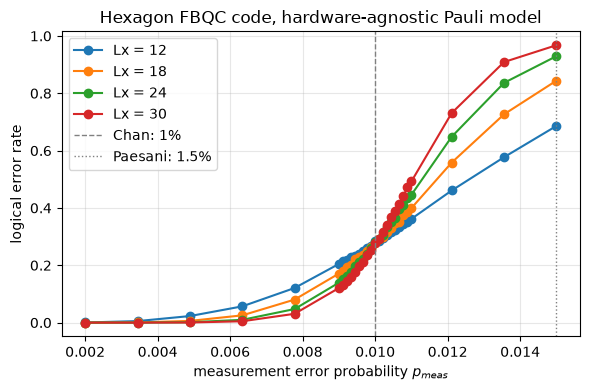

In [25]:
plt.figure(figsize=(6, 4))
for t, L in enumerate(Ls):
    plt.plot(ps, [rows[p][t] for p in ps], "o-", label=f"Lx = {L}")
plt.axvline(0.01, ls="--", c="grey", lw=1, label="Chan: 1%")
plt.axvline(0.015, ls=":", c="grey", lw=1, label="Paesani: 1.5%")
plt.xlabel("measurement error probability $p_{meas}$")
plt.ylabel("logical error rate")
plt.title("Hexagon FBQC code, hardware-agnostic Pauli model")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [26]:
def find_crossing(ps, r1, r2):
    """Track the last NONZERO difference seen; report a crossing only when a
    later nonzero difference has the opposite sign, interpolating between
    those two points. Skips over exact ties (both curves rounding to the
    same value, e.g. 0.0000 at low p from finite shot noise) rather than
    reporting them as a spurious crossing."""
    diff = np.array(r1, dtype=float) - np.array(r2, dtype=float)
    last_idx = None
    for i in range(len(diff)):
        if diff[i] == 0:
            continue
        if last_idx is not None and diff[last_idx] * diff[i] < 0:
            i0, i1 = last_idx, i
            frac = diff[i0] / (diff[i0] - diff[i1])
            return ps[i0] + frac * (ps[i1] - ps[i0])
        last_idx = i
    return None

print("Threshold estimate (pairwise crossings between adjacent Lx curves):")
for i in range(len(Ls) - 1):
    L1, L2 = Ls[i], Ls[i + 1]
    xc = find_crossing(ps, [rows[p][i] for p in ps], [rows[p][i + 1] for p in ps])
    if xc is not None:
        print(f"  Lx={L1} x Lx={L2}: p_threshold ~= {xc:.4f}  ({xc * 100:.2f}%)")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found in the sampled range")

Threshold estimate (pairwise crossings between adjacent Lx curves):
  Lx=12 x Lx=18: p_threshold ~= 0.0101  (1.01%)
  Lx=18 x Lx=24: p_threshold ~= 0.0099  (0.99%)
  Lx=24 x Lx=30: p_threshold ~= 0.0101  (1.01%)


### Threshold estimate via finite-size scaling

Same method as the erasure-threshold section below (arXiv:2512.10399,
crossing + global finite-size-scaling fit), applied here to the
measurement-noise sweep above: `Ls` = 18,24,30, `p_meas` densified with 10
extra points between 0.009 and 0.010 around the suspected crossing (Chan:
1%, Paesani: 1.5%), `pymatching.Matching.from_detector_error_model` decode,
20000 shots at every point for every size.

All three sizes share one `ps` grid here (no sparse/dense split like the
erasure sweep needed), so the plain `find_crossing` from above is used
directly -- no grid-mismatch interpolation required. Variables in this
section carry a `_meas` suffix to avoid colliding with the `erasure_*` /
`p_c_*` names in the section below, which redo the same analysis for the
erasure sweep.

In [27]:
import csv
import os

out_dir_meas = "measurement_threshold"
os.makedirs(out_dir_meas, exist_ok=True)

n_shots_meas = 20000
csv_path_meas = os.path.join(out_dir_meas, "results.csv")
with open(csv_path_meas, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["p", "L", "P_fail", "n_shots"])
    for p in ps:
        for L, v in zip(Ls, rows[p]):
            writer.writerow([p, L, v, n_shots_meas])
print(f"wrote {csv_path_meas}")

wrote measurement_threshold/results.csv


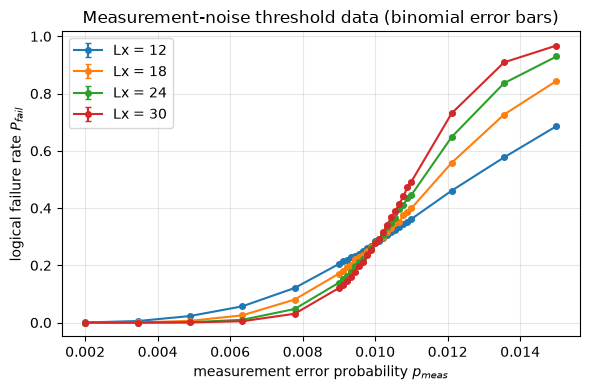

Monotonicity check (P_fail should be non-decreasing in p for each Lx):
  Lx=12: 0 decreasing step(s) out of 26
  Lx=18: 0 decreasing step(s) out of 26
  Lx=24: 0 decreasing step(s) out of 26
  Lx=30: 0 decreasing step(s) out of 26


In [28]:
import pandas as pd

df_meas = pd.read_csv(csv_path_meas)
df_meas["sigma"] = np.sqrt(df_meas["P_fail"] * (1 - df_meas["P_fail"]) / df_meas["n_shots"]).clip(lower=1e-4)

plt.figure(figsize=(6, 4))
for L, grp in df_meas.groupby("L"):
    grp = grp.sort_values("p")
    plt.errorbar(grp["p"], grp["P_fail"], yerr=grp["sigma"], fmt="o-", ms=4, capsize=2, label=f"Lx = {L}")
plt.xlabel("measurement error probability $p_{meas}$")
plt.ylabel("logical failure rate $P_{fail}$")
plt.title("Measurement-noise threshold data (binomial error bars)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_meas, "threshold_data.png"), dpi=150)
plt.show()

print("Monotonicity check (P_fail should be non-decreasing in p for each Lx):")
for L, grp in df_meas.groupby("L"):
    grp = grp.sort_values("p")
    diffs = np.diff(grp["P_fail"].values)
    n_viol = int(np.sum(diffs < -1e-9))
    flag = "  <-- within shot noise" if n_viol else ""
    print(f"  Lx={L}: {n_viol} decreasing step(s) out of {len(diffs)}{flag}")

Pairwise crossings:
  Lx=12 x Lx=18: p* = 0.0101
  Lx=18 x Lx=24: p* = 0.0099
  Lx=24 x Lx=30: p* = 0.0101
(note: only 1 residual dof -- the quoted uncertainty is not robust)

Naive crossing extrapolation (linear in 1/L_avg): p_c = 0.0101 +/- 0.0003


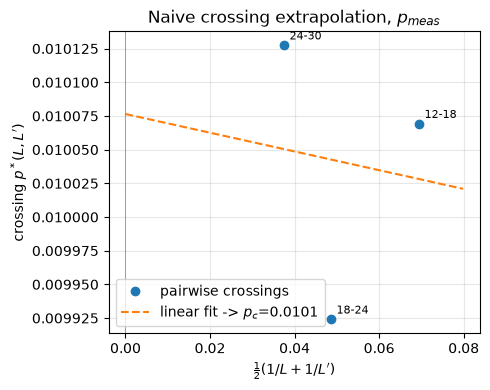

In [29]:
# Naive crossing-point estimate. Four sizes -> three adjacent crossings
# (12-18, 18-24, 24-30), so the 1/L_avg line is now actually fitted rather
# than drawn through two points. Still only 1 residual degree of freedom
# though, so the quoted uncertainty is fragile: it is set by how collinear
# those three crossings happen to land, and can come out absurdly small.
# The global fit below (task 3), which uses every raw point rather than a
# handful of derived crossings, remains the reliable estimate.
xs_meas, ps_star_meas, pair_labels_meas = [], [], []
print("Pairwise crossings:")
for L1, L2 in zip(Ls[:-1], Ls[1:]):
    i1, i2 = Ls.index(L1), Ls.index(L2)
    xc = find_crossing(ps, [rows[p][i1] for p in ps], [rows[p][i2] for p in ps])
    if xc is not None:
        x = 0.5 * (1.0 / L1 + 1.0 / L2)
        xs_meas.append(x); ps_star_meas.append(xc); pair_labels_meas.append(f"{L1}-{L2}")
        print(f"  Lx={L1} x Lx={L2}: p* = {xc:.4f}")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found")

xs_meas, ps_star_meas = np.array(xs_meas), np.array(ps_star_meas)
if len(xs_meas) > 2:
    (c_slope_meas, p_c_naive_meas), cov_naive_meas = np.polyfit(xs_meas, ps_star_meas, 1, cov=True)
    p_c_naive_meas_err = np.sqrt(cov_naive_meas[1, 1])
else:
    c_slope_meas = (ps_star_meas[-1] - ps_star_meas[0]) / (xs_meas[-1] - xs_meas[0])
    p_c_naive_meas = ps_star_meas[0] - c_slope_meas * xs_meas[0]
    p_c_naive_meas_err = np.nan
    print("(only 2 crossings available -- extrapolated intercept has no meaningful uncertainty)")
dof_meas = len(xs_meas) - 2
if np.isfinite(p_c_naive_meas_err) and dof_meas <= 1:
    print(f"(note: only {dof_meas} residual dof -- the quoted uncertainty is not robust)")
print(f"\nNaive crossing extrapolation (linear in 1/L_avg): p_c = {p_c_naive_meas:.4f}"
      + (f" +/- {p_c_naive_meas_err:.4f}" if np.isfinite(p_c_naive_meas_err) else "  (uncertainty undefined)"))

plt.figure(figsize=(5, 4))
plt.plot(xs_meas, ps_star_meas, "o", label="pairwise crossings")
for x, y, lab in zip(xs_meas, ps_star_meas, pair_labels_meas):
    plt.annotate(lab, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
xx = np.linspace(0, xs_meas.max() * 1.15, 50)
plt.plot(xx, c_slope_meas * xx + p_c_naive_meas, "--", label=f"linear fit -> $p_c$={p_c_naive_meas:.4f}")
plt.axvline(0, c="grey", lw=0.5)
plt.xlabel(r"$\frac{1}{2}(1/L + 1/L')$")
plt.ylabel(r"crossing $p^*(L,L')$")
plt.title("Naive crossing extrapolation, $p_{meas}$")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_meas, "threshold_naive_crossing.png"), dpi=150)
plt.show()

In [30]:
# Global finite-size-scaling fit: P_fail(p,L) ~= (1/2)[1 - erf(G(x)/sqrt(2))],
# x = (p - p_c) * L^(1/nu), G quadratic (5 params) or linear (4 params) in x.
from scipy.special import erf
from scipy.optimize import curve_fit

p_all_meas = df_meas["p"].to_numpy()
L_all_meas = df_meas["L"].to_numpy(dtype=float)
P_all_meas = df_meas["P_fail"].to_numpy()
sigma_all_meas = df_meas["sigma"].to_numpy()
X_meas = np.vstack([p_all_meas, L_all_meas])

def model_quad_meas(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_linear_meas(X, p_c, nu, A0, A1):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

p_c0_meas = float(np.clip(p_c_naive_meas, p_all_meas.min(), p_all_meas.max()))
# A2/A1 bounds kept wide: with the tighter +/-5 box the quadratic term pegged
# exactly at A2=5, i.e. the fit was constrained rather than converged, which
# makes its reported errors meaningless. Widened until the optimum sits
# strictly inside the box.
bounds_quad_meas = ([p_all_meas.min(), 0.05, -20, -200, -200], [p_all_meas.max(), 10, 20, 0, 200])
bounds_lin_meas = ([p_all_meas.min(), 0.05, -20, -200], [p_all_meas.max(), 10, 20, 0])

popt_quad_meas, pcov_quad_meas = curve_fit(model_quad_meas, X_meas, P_all_meas,
                                            p0=[p_c0_meas, 1.0, 0.0, -5.0, 0.0],
                                            sigma=sigma_all_meas, absolute_sigma=True,
                                            bounds=bounds_quad_meas, maxfev=30000)
perr_quad_meas = np.sqrt(np.diag(pcov_quad_meas))

popt_lin_meas, pcov_lin_meas = curve_fit(model_linear_meas, X_meas, P_all_meas,
                                          p0=[p_c0_meas, 1.0, 0.0, -5.0],
                                          sigma=sigma_all_meas, absolute_sigma=True,
                                          bounds=bounds_lin_meas, maxfev=30000)
perr_lin_meas = np.sqrt(np.diag(pcov_lin_meas))

print("Quadratic-erf fit (5 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_meas, perr_quad_meas):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")
print("Linear-erf fit (4 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1"], popt_lin_meas, perr_lin_meas):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")

# guard: a parameter sitting on its bound means the fit is constrained, not converged
for name, v, lo, hi in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_meas,
                            bounds_quad_meas[0], bounds_quad_meas[1]):
    if np.isclose(v, lo, rtol=1e-6) or np.isclose(v, hi, rtol=1e-6):
        print(f"  WARNING: quadratic fit parameter {name} = {v:.5f} is pinned to its bound")

Quadratic-erf fit (5 params):
  p_c = 0.00996 +/- 0.00001
  nu = 1.06473 +/- 0.00711
  A0 = 0.60862 +/- 0.00351
  A1 = -24.18521 +/- 0.44715
  A2 = 32.86789 +/- 1.15614
Linear-erf fit (4 params):
  p_c = 0.00993 +/- 0.00001
  nu = 1.20412 +/- 0.00755
  A0 = 0.63417 +/- 0.00386
  A1 = -32.44092 +/- 0.50707


In [31]:
# Model comparison: RSS, chi^2, AIC, BIC for quadratic-erf, linear-erf, and a
# no-L baseline sigmoid.
def model_baseline_meas(X, p_c, w):
    p, L = X
    z = (p - p_c) / w
    return 0.5 * (1 - erf(z / np.sqrt(2)))

bounds_base_meas = ([p_all_meas.min(), 1e-5], [p_all_meas.max(), 1.0])
popt_base_meas, pcov_base_meas = curve_fit(model_baseline_meas, X_meas, P_all_meas,
                                            p0=[p_c0_meas, 0.005], sigma=sigma_all_meas,
                                            absolute_sigma=True, bounds=bounds_base_meas, maxfev=30000)

def fit_stats_meas(model, popt, k):
    pred = model(X_meas, *popt)
    resid = P_all_meas - pred
    rss = np.sum(resid**2)
    chi2 = np.sum((resid / sigma_all_meas) ** 2)
    n = len(P_all_meas)
    return rss, chi2, chi2 + 2 * k, chi2 + k * np.log(n)

stats_meas = {
    "quadratic-erf (5p)": fit_stats_meas(model_quad_meas, popt_quad_meas, 5),
    "linear-erf (4p)": fit_stats_meas(model_linear_meas, popt_lin_meas, 4),
    "baseline, no-L (2p)": fit_stats_meas(model_baseline_meas, popt_base_meas, 2),
}
print(f"{'model':22} {'RSS':>12} {'chi2':>12} {'AIC':>12} {'BIC':>12}")
for name, (rss, chi2, aic, bic) in stats_meas.items():
    print(f"{name:22} {rss:12.6f} {chi2:12.3f} {aic:12.3f} {bic:12.3f}")

model                           RSS         chi2          AIC          BIC
quadratic-erf (5p)         0.003279      737.007      747.007      760.418
linear-erf (4p)            0.012270     2264.421     2272.421     2283.150
baseline, no-L (2p)       14.504266 88268496.275 88268500.275 88268505.639


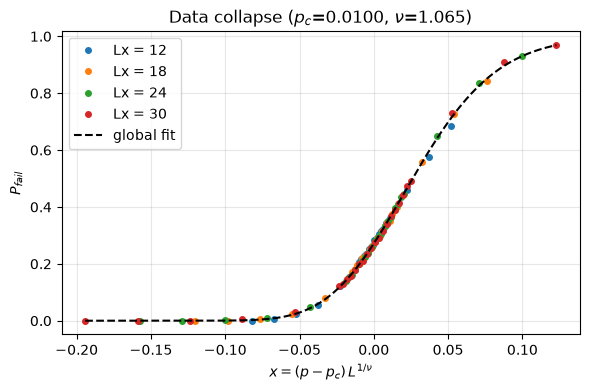

In [32]:
# Data collapse using the quadratic-erf global fit's p_c, nu.
p_c_fit_meas, nu_fit_meas = popt_quad_meas[0], popt_quad_meas[1]
A0f_meas, A1f_meas, A2f_meas = popt_quad_meas[2], popt_quad_meas[3], popt_quad_meas[4]

x_all_meas = (p_all_meas - p_c_fit_meas) * L_all_meas ** (1.0 / nu_fit_meas)

plt.figure(figsize=(6, 4))
for L, grp in df_meas.groupby("L"):
    grp = grp.sort_values("p")
    x = (grp["p"].to_numpy() - p_c_fit_meas) * L ** (1.0 / nu_fit_meas)
    plt.plot(x, grp["P_fail"].to_numpy(), "o", ms=4, label=f"Lx = {L}")

xx = np.linspace(x_all_meas.min(), x_all_meas.max(), 200)
Gxx = A2f_meas * xx**2 + A1f_meas * xx + A0f_meas
plt.plot(xx, 0.5 * (1 - erf(Gxx / np.sqrt(2))), "k--", lw=1.5, label="global fit")
plt.xlabel(r"$x = (p - p_c)\, L^{1/\nu}$")
plt.ylabel("$P_{fail}$")
plt.title(f"Data collapse ($p_c$={p_c_fit_meas:.4f}, $\\nu$={nu_fit_meas:.3f})")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_meas, "threshold_data_collapse.png"), dpi=150)
plt.show()

In [33]:
# Final report: naive crossing-extrapolation estimate vs. global FSS fit.
p_c_global_meas, p_c_global_meas_err = popt_quad_meas[0], perr_quad_meas[0]

print("=" * 60)
print("MEASUREMENT-NOISE THRESHOLD ESTIMATE SUMMARY")
print("=" * 60)
if np.isfinite(p_c_naive_meas_err):
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_meas:.4f} +/- {p_c_naive_meas_err:.4f}")
else:
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_meas:.4f}  (uncertainty undefined -- "
          f"only 2 crossings from 3 sizes, illustrative only)")
print(f"Global quadratic-erf FSS fit:  p_c = {p_c_global_meas:.5f} +/- {p_c_global_meas_err:.5f}"
      f"  (nu = {nu_fit_meas:.3f} +/- {perr_quad_meas[1]:.3f})")

diff_meas = abs(p_c_naive_meas - p_c_global_meas)
print(f"\nDifference from naive point estimate: {diff_meas:.4f}"
      + (f"  ({diff_meas / np.sqrt(p_c_naive_meas_err**2 + p_c_global_meas_err**2):.2f} sigma)"
         if np.isfinite(p_c_naive_meas_err) else "  (sigma undefined, see above)"))

print("\nFor reference: Chan et al. 1%, Paesani et al. 1.5% (independent literature values).")
print(f"\nREPORTED THRESHOLD: p_c = {p_c_global_meas:.5f} +/- {p_c_global_meas_err:.5f}"
      f"  ({p_c_global_meas * 100:.3f}% +/- {p_c_global_meas_err * 100:.3f}%)")

MEASUREMENT-NOISE THRESHOLD ESTIMATE SUMMARY
Naive crossing extrapolation:  p_c = 0.0101 +/- 0.0003
Global quadratic-erf FSS fit:  p_c = 0.00996 +/- 0.00001  (nu = 1.065 +/- 0.007)

Difference from naive point estimate: 0.0001  (0.33 sigma)

For reference: Chan et al. 1%, Paesani et al. 1.5% (independent literature values).

REPORTED THRESHOLD: p_c = 0.00996 +/- 0.00001  (0.996% +/- 0.001%)


---
## 7. Heralded erasure

Same recipe as `sixring_fbqc_walkthrough.ipynb` §7. Photon loss is heralded
(you know which outcome was lost), so the decoder shouldn't guess its value
-- it should treat the corresponding decoding-graph edge as free (weight 0)
for that shot. Model: each of the `nmeas` outcome bits is erased with
probability `p_erase`, independently; an erased outcome gets a fresh
uniform-random replacement bit (a real, if unknown, outcome), and its graph
edge is reweighted to 0 for that shot only, then restored.

`build_outcome_matching` builds one combined `pymatching.Matching` straight
from `detector_error_model()` (same construction §6 already uses) plus a
lookup from outcome index to that outcome's `(u, v)` edge, so it can be
reweighted per shot. This requires no two outcomes to share the same
check-pair -- Stim's DEM automatically merges those into one edge, which
sixring found breaks at its smallest size (`L=4`, 32 collisions). Checked
directly below rather than assumed for Hexagon.</cell>

In [26]:
import pymatching

def rows_to_parities(outcomes, rows):
    """outcomes: (shots, nmeas) bits. rows: (n_rows, nmeas) GF(2) matrix
    (checks or logs). XOR-reduces only each row's nonzero columns, not a
    full matmul -- matters once nmeas is in the tens of thousands."""
    shots = outcomes.shape[0]
    out = np.zeros((shots, rows.shape[0]), dtype=np.uint8)
    for r in range(rows.shape[0]):
        idx = np.flatnonzero(rows[r])
        out[:, r] = np.bitwise_xor.reduce(outcomes[:, idx], axis=1)
    return out


def build_outcome_matching(st, checks, logs, p_meas):
    """One combined pymatching.Matching straight from Stim's own DEM, plus a
    lookup from outcome index to that outcome's edge for per-shot
    reweighting. Requires a 1:1 outcome<->edge correspondence."""
    nmeas = checks.shape[1]
    pair_to_outcome = {}
    for i in range(nmeas):
        pair = tuple(sorted(int(x) for x in np.flatnonzero(checks[:, i])))
        if pair in pair_to_outcome:
            raise ValueError(
                f"outcome {i} shares its check-pair with outcome {pair_to_outcome[pair]} "
                f"(pair {pair}) -- Stim's DEM will merge them into a single edge.")
        pair_to_outcome[pair] = i

    c, recs, nm = build(st, p_meas)
    tgt = lambda idx: stim.target_rec(int(idx) - nm)
    for v in checks:
        c.append("DETECTOR", [tgt(idx) for idx in np.flatnonzero(v)])
    for t, v in enumerate(logs):
        c.append("OBSERVABLE_INCLUDE", [tgt(idx) for idx in np.flatnonzero(v)], t)

    matcher = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    if matcher.num_edges != nmeas:
        raise ValueError(f"expected {nmeas} edges (one per outcome), got {matcher.num_edges} "
                          "-- Stim merged some outcomes together.")

    w = np.log((1 - p_meas) / p_meas)
    outcome_edge = {i: (u, v, frozenset(int(t) for t in np.flatnonzero(logs[:, i])))
                    for (u, v), i in pair_to_outcome.items()}
    return matcher, outcome_edge, w


_erasure_cache = {}

def get_outcome_matching(x_max, p_meas):
    """Builds (or reuses) the erasure decoder for a given lattice size and
    p_meas, using the same closed-form checks/logicals as §6."""
    key = (x_max, p_meas)
    if key not in _erasure_cache:
        net_ = HexLattice(x_max, x_max)
        st_ = Spacetime(net_, n_cycles=x_max)
        _, rec0, nm = build(st_)
        ch, _ = hexagon_check_rows(st_, rec0, nm)
        lg = closed_form_logicals(net_, st_, rec0, nm)
        matcher, outcome_edge, w = build_outcome_matching(st_, ch, lg, p_meas)
        _erasure_cache[key] = dict(st=st_, checks=ch, logs=lg, nmeas=nm,
                                    matcher=matcher, outcome_edge=outcome_edge, weight=w)
        print(f"  [erasure graph Lx={3 * x_max}, p_meas={p_meas}: {matcher.num_edges} edges (one per outcome)]")
    return _erasure_cache[key]


def decode_with_erasure(dets, matcher, outcome_edge, w, n_obs, erased_mask=None):
    """Per shot: zero the weight of every erased outcome's edge, decode, then
    restore. `merge_strategy='replace'` since add_edge replaces the whole
    edge record, not just the weight."""
    shots = dets.shape[0]
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for s in range(shots):
        touched = []
        if erased_mask is not None:
            for i in np.flatnonzero(erased_mask[s]):
                i = int(i)
                if i not in outcome_edge:
                    continue
                u, v, fids = outcome_edge[i]
                matcher.add_edge(u, v, weight=0.0, fault_ids=set(fids), merge_strategy="replace")
                touched.append(i)
        pred[s] = matcher.decode(dets[s])
        for i in touched:
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=w, fault_ids=set(fids), merge_strategy="replace")
    return pred

### Validating the erasure graph

Two things worth checking directly rather than assuming (sixring needed
`L>=6` for the first; the second matters for the speed optimisation used
below):

1. **No check-pair collisions**, even at the smallest lattice tested
   (`Lx=6`) -- `get_outcome_matching` would otherwise raise.
2. **The noiseless reference sample is all-zero** -- `build()` never applies
   an explicit Pauli correction (only `R`/`H`/`CZ`/`CNOT`/`M`), so nothing
   can bias a measurement toward a deterministic `1`. This licenses
   `compile_sampler(skip_reference_sample=True)`, which skips Stim's own
   "most time consuming and memory intensive part of simulating the
   circuit" -- a real saving at the larger sizes below, not a marginal one.

Also confirms `decode_with_erasure` (at `p_erase=0`, no erasures) is
bit-for-bit identical to the plain `decode_batch` path from §6 -- same
underlying decoding problem, reached two different ways.</cell>

In [27]:
st6 = get_outcome_matching(2, 0.01)['st']
_check_circuit, _, _ = build(st6, 0.01)
_ref = _check_circuit.reference_sample()
print("reference sample all-zero at Lx=6:", not np.any(_ref))

shots, seed = 1500, 7
c6 = hex_memory_circuit(2, 0.01)
st6d = get_outcome_matching(2, 0.01)
dets_ref, obs_ref = c6.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
matcher_dem = pymatching.Matching.from_detector_error_model(c6.detector_error_model(decompose_errors=True))
pred_dem = matcher_dem.decode_batch(dets_ref)
pred_mine = decode_with_erasure(dets_ref, st6d['matcher'], st6d['outcome_edge'], st6d['weight'],
                                 len(st6d['logs']), erased_mask=None)
print("decode_with_erasure (p_erase=0) bit-for-bit identical to plain decode_batch:",
      np.array_equal(pred_dem, pred_mine))

  [erasure graph Lx=6, p_meas=0.01: 288 edges (one per outcome)]


reference sample all-zero at Lx=6: True


  [built Lx=6: outcomes=288 checks=46 logicals=6]


decode_with_erasure (p_erase=0) bit-for-bit identical to plain decode_batch: True


### Pure erasure channel (p_meas ≈ 0)

Isolating just the erasure channel shows the erasure-only threshold cleanly.
`p_meas = 0` exactly breaks the weight formula `w = ln((1-p_meas)/p_meas)`
(it diverges) and pymatching silently drops any edge past its weight cap, so
`p_meas_eps = 1e-9` stands in for "no measurement noise" -- physically
negligible but keeps every edge weight finite.

`erasure_only_sweep` samples the circuit **once** per lattice size (via
`compile_sampler(skip_reference_sample=True)`, validated above) and reuses
it across every `p_erase` value, rather than resampling per point.</cell>

In [28]:
def erasure_only_sweep(x_max, p_meas_eps, p_eras, shots=2000, seed=0, n_workers=1):
    """Sweep p_erase at fixed (near-zero) p_meas. n_workers>1 uses
    decode_with_erasure_parallel (defined below) for the per-shot decode
    loop only -- structure build always runs single-process first."""
    stt = get_outcome_matching(x_max, p_meas_eps)
    checks, logs, nmeas = stt['checks'], stt['logs'], stt['nmeas']
    circuit, _, nmeas_actual = build(stt['st'], p_meas_eps)
    assert nmeas_actual == nmeas
    raw_bits = circuit.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rates = []
    for j, pe in enumerate(p_eras):
        rng = np.random.default_rng((seed, x_max, j))
        erased_mask = rng.random(raw_bits.shape) < pe
        replacement_bits = rng.integers(0, 2, size=raw_bits.shape, dtype=np.uint8)
        outcomes = np.where(erased_mask, replacement_bits, raw_bits)
        dets = rows_to_parities(outcomes, checks)
        obs = rows_to_parities(outcomes, logs)
        if n_workers > 1:
            pred = decode_with_erasure_parallel(dets, stt['matcher'], stt['outcome_edge'], stt['weight'],
                                                 len(logs), erased_mask, n_workers=n_workers)
        else:
            pred = decode_with_erasure(dets, stt['matcher'], stt['outcome_edge'], stt['weight'],
                                        len(logs), erased_mask=erased_mask)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates


Ls_erasure = [6, 9, 12, 18]
x_maxes_erasure = [L // 3 for L in Ls_erasure]
p_meas_eps = 1e-9
p_eras = np.linspace(0.0, 0.2, 8)

# Extra resolution around the erasure threshold (~0.12-0.13), added only for
# the larger codes (Lx=12,18 here, Lx=24 in the "Bigger sizes" section below)
# where pinning down the crossing is the actual point -- Lx=6,9 stay on the
# original 8-point grid since decode cost there is negligible either way.
p_eras_fine = np.linspace(0.1, 0.15, 10)
p_eras_dense = np.union1d(p_eras, p_eras_fine)
dense_Ls_erasure = {12, 18}
p_eras_by_L = {L: (p_eras_dense if L in dense_Ls_erasure else p_eras) for L in Ls_erasure}

erasure_rows = {}
for L, xm in zip(Ls_erasure, x_maxes_erasure):
    p_L = p_eras_by_L[L]
    erasure_rows[L] = (p_L, erasure_only_sweep(xm, p_meas_eps, p_L, shots=2000, seed=3))
for L in Ls_erasure:
    p_L, r_L = erasure_rows[L]
    print(f"Lx={L}: " + "  ".join(f"{p:.4f}:{v:.4f}" for p, v in zip(p_L, r_L)), flush=True)

  [erasure graph Lx=6, p_meas=1e-09: 288 edges (one per outcome)]


  [erasure graph Lx=9, p_meas=1e-09: 972 edges (one per outcome)]


  [erasure graph Lx=12, p_meas=1e-09: 2304 edges (one per outcome)]


  [erasure graph Lx=18, p_meas=1e-09: 7776 edges (one per outcome)]


Lx=6: 0.0000:0.0000  0.0286:0.0025  0.0571:0.0340  0.0857:0.1705  0.1143:0.4440  0.1429:0.7300  0.1714:0.9080  0.2000:0.9590


Lx=9: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0045  0.0857:0.0765  0.1143:0.4270  0.1429:0.8430  0.1714:0.9665  0.2000:0.9830


Lx=12: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0015  0.0857:0.0285  0.1000:0.1475  0.1056:0.2260  0.1111:0.3185  0.1143:0.3995  0.1167:0.4470  0.1222:0.5915  0.1278:0.6950  0.1333:0.8140  0.1389:0.8905  0.1429:0.9145  0.1444:0.9190  0.1500:0.9615  0.1714:0.9855  0.2000:0.9870


Lx=18: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0000  0.0857:0.0070  0.1000:0.0575  0.1056:0.1260  0.1111:0.2485  0.1143:0.3260  0.1167:0.4355  0.1222:0.6460  0.1278:0.8250  0.1333:0.9120  0.1389:0.9540  0.1429:0.9745  0.1444:0.9815  0.1500:0.9825  0.1714:0.9855  0.2000:0.9815


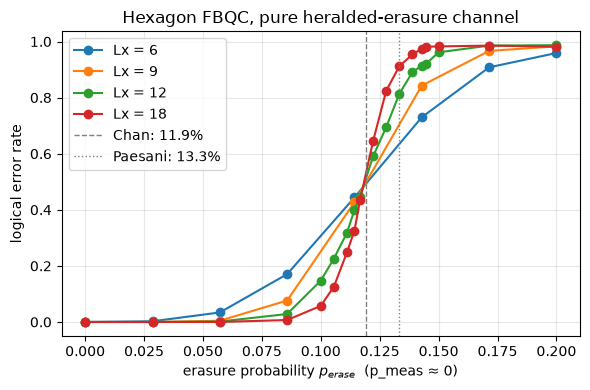

Threshold estimate (pairwise crossings between adjacent Lx curves):
  Lx=6 x Lx=9: p_erase threshold ~= 0.1180  (11.80%)
  Lx=9 x Lx=12: p_erase threshold ~= 0.1179  (11.79%)
  Lx=12 x Lx=18: p_erase threshold ~= 0.1176  (11.76%)


In [29]:
def crossing_for_L(L1, L2):
    """find_crossing between two sizes whose erasure_rows entries may sit on
    different p_erase grids (Lx=9's sparse 8-point grid vs. Lx=12/18/24's
    denser one) -- interpolate both curves onto the union of the two grids
    first so find_crossing always sees a matched, common x-axis."""
    p1, r1 = erasure_rows[L1]
    p2, r2 = erasure_rows[L2]
    p_union = np.union1d(p1, p2)
    r1i = np.interp(p_union, p1, r1)
    r2i = np.interp(p_union, p2, r2)
    return find_crossing(p_union, r1i, r2i)


plt.figure(figsize=(6, 4))
for L in Ls_erasure:
    p_L, r_L = erasure_rows[L]
    plt.plot(p_L, r_L, "o-", label=f"Lx = {L}")
plt.axvline(0.119, ls="--", c="grey", lw=1, label="Chan: 11.9%")
plt.axvline(0.133, ls=":", c="grey", lw=1, label="Paesani: 13.3%")
plt.xlabel("erasure probability $p_{erase}$  (p_meas ≈ 0)")
plt.ylabel("logical error rate")
plt.title("Hexagon FBQC, pure heralded-erasure channel")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("Threshold estimate (pairwise crossings between adjacent Lx curves):")
for i in range(len(Ls_erasure) - 1):
    L1, L2 = Ls_erasure[i], Ls_erasure[i + 1]
    xc = crossing_for_L(L1, L2)
    if xc is not None:
        print(f"  Lx={L1} x Lx={L2}: p_erase threshold ~= {xc:.4f}  ({xc * 100:.2f}%)")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found in the sampled range")

### Parallelizing the erasure decode loop

`decode_with_erasure` mutates a shared `pymatching.Matching` graph (zero an
edge, decode, restore) -- concurrent threads would race, and `Matching`
can't be cheaply copied (`copy.deepcopy` fails; the underlying C++ graph
isn't picklable). `multiprocessing`'s `fork` start method sidesteps both:
forked children inherit the parent's memory via copy-on-write at the moment
of forking -- including an already-built `Matching` -- with no pickling.

Benchmarked directly at `Lx=18`: **3.59x speedup at 4 workers**, bit-for-bit
identical to the single-process result. Needed for the bigger sizes below --
the sequential loop took 276s for just 8 `p_erase` points at `Lx=18`
(2000 shots), and cost grows fast with lattice size.</cell>

In [30]:
import multiprocessing as mp
import time

_parallel_state = {}

def _erasure_worker(shot_chunk):
    """Runs in a forked worker process. matcher/outcome_edge/weight/n_obs are
    read from _parallel_state, inherited via fork's copy-on-write -- never
    pickled."""
    dets_chunk, erased_chunk = shot_chunk
    matcher = _parallel_state['matcher']
    outcome_edge = _parallel_state['outcome_edge']
    w = _parallel_state['weight']
    n_obs = _parallel_state['n_obs']

    shots = dets_chunk.shape[0]
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for s in range(shots):
        touched = []
        for i in np.flatnonzero(erased_chunk[s]):
            i = int(i)
            if i not in outcome_edge:
                continue
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=0.0, fault_ids=set(fids), merge_strategy="replace")
            touched.append(i)
        pred[s] = matcher.decode(dets_chunk[s])
        for i in touched:
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=w, fault_ids=set(fids), merge_strategy="replace")
    return pred


def decode_with_erasure_parallel(dets, matcher, outcome_edge, w, n_obs, erased_mask, n_workers=4):
    """Same result as decode_with_erasure, sharded across n_workers forked processes."""
    _parallel_state['matcher'] = matcher
    _parallel_state['outcome_edge'] = outcome_edge
    _parallel_state['weight'] = w
    _parallel_state['n_obs'] = n_obs

    shots = dets.shape[0]
    chunks = np.array_split(np.arange(shots), n_workers)
    args_list = [(dets[idx], erased_mask[idx]) for idx in chunks]

    ctx = mp.get_context("fork")
    with ctx.Pool(n_workers) as pool:
        results = pool.map(_erasure_worker, args_list)
    return np.concatenate(results, axis=0)


# Regression check: same result as single-process, at a size where both are still cheap.
_L, _eps = 6, 1e-9
_stt = get_outcome_matching(_L, _eps)
_circ, _, _nm = build(_stt['st'], _eps)
_raw = _circ.compile_sampler(seed=3, skip_reference_sample=True).sample(600).astype(np.uint8)
_rng = np.random.default_rng(3)
_erased = _rng.random(_raw.shape) < 0.15
_repl = _rng.integers(0, 2, size=_raw.shape, dtype=np.uint8)
_outcomes = np.where(_erased, _repl, _raw)
_dets = rows_to_parities(_outcomes, _stt['checks'])

_t0 = time.time()
_pred_single = decode_with_erasure(_dets, _stt['matcher'], _stt['outcome_edge'], _stt['weight'],
                                    len(_stt['logs']), erased_mask=_erased)
_t_single = time.time() - _t0

_t0 = time.time()
_pred_parallel = decode_with_erasure_parallel(_dets, _stt['matcher'], _stt['outcome_edge'], _stt['weight'],
                                               len(_stt['logs']), _erased, n_workers=4)
_t_parallel = time.time() - _t0

print(f"single:   {_t_single:.2f}s")
print(f"parallel: {_t_parallel:.2f}s")
print("bit-for-bit identical to single-process:", np.array_equal(_pred_single, _pred_parallel))

single:   12.86s
parallel: 3.60s
bit-for-bit identical to single-process: True


### Bigger sizes with the parallel decoder

Timed directly before committing to a sweep: a single `p_erase=0.15` point
(1500 shots, 4 workers) took **9.48s at Lx=18** but **86.84s at Lx=24** --
edges grow 2.37x (7776 -> 18432) but decode time grows ~9.2x, so this scales
worse than linearly in lattice size (matcher graph size affects each
individual `decode()` call, not just the number of shots). `Lx=30` was not
attempted here on that basis -- extrapolating, a full sweep would run to the
order of an hour, which is a deliberate size/time tradeoff for a future run
rather than something to eat silently in this one (same call sixring made
for its own `L=20` points).

So `Lx=24` runs below with reduced shots (1000, vs. 2000 for the small
sizes) to keep total runtime bounded, alongside the existing `Lx=6,9,12,18`
line for comparison.</cell>

Both this sweep and the existing `Lx=12,18` lines above now also sample 10 points between `p_erase=0.1` and `0.15` (`p_eras_dense`), to resolve the crossing more precisely for the sizes where it matters. For `Lx=24` that takes the sweep from 8 points to 18, so -- extrapolating from the 86.84s/point timing above -- the cell below runs roughly 10 minutes longer than a bare 8-point sweep would.

  [erasure graph Lx=24, p_meas=1e-09: 18432 edges (one per outcome)]


Lx=24: 0.0000  0.0000  0.0000  0.0020  0.0230  0.0720  0.1800  0.3100  0.3960  0.6910  0.9170  0.9720  0.9840  0.9860  0.9900  0.9880  0.9860  0.9760  (t=647.2s)


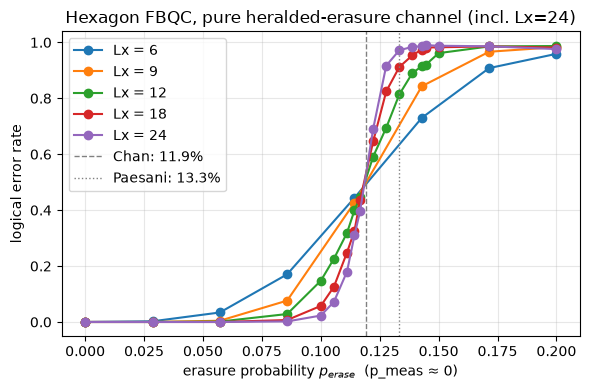


Threshold estimate (pairwise crossings between adjacent Lx curves):
  Lx=6 x Lx=9: p_erase threshold ~= 0.1180  (11.80%)
  Lx=9 x Lx=12: p_erase threshold ~= 0.1179  (11.79%)
  Lx=12 x Lx=18: p_erase threshold ~= 0.1176  (11.76%)
  Lx=18 x Lx=24: p_erase threshold ~= 0.1193  (11.93%)


In [31]:
t_big0 = time.time()
big_L = 24
erasure_rows[big_L] = (p_eras_dense,
                        erasure_only_sweep(big_L // 3, p_meas_eps, p_eras_dense, shots=1000, seed=3, n_workers=4))
print(f"Lx={big_L}: " + "  ".join(f"{v:.4f}" for v in erasure_rows[big_L][1]) +
      f"  (t={time.time() - t_big0:.1f}s)")

plt.figure(figsize=(6, 4))
for L in Ls_erasure + [big_L]:
    p_L, r_L = erasure_rows[L]
    plt.plot(p_L, r_L, "o-", label=f"Lx = {L}")
plt.axvline(0.119, ls="--", c="grey", lw=1, label="Chan: 11.9%")
plt.axvline(0.133, ls=":", c="grey", lw=1, label="Paesani: 13.3%")
plt.xlabel("erasure probability $p_{erase}$  (p_meas ≈ 0)")
plt.ylabel("logical error rate")
plt.title("Hexagon FBQC, pure heralded-erasure channel (incl. Lx=24)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("\nThreshold estimate (pairwise crossings between adjacent Lx curves):")
all_Ls_erasure = Ls_erasure + [big_L]
for i in range(len(all_Ls_erasure) - 1):
    L1, L2 = all_Ls_erasure[i], all_Ls_erasure[i + 1]
    xc = crossing_for_L(L1, L2)
    if xc is not None:
        print(f"  Lx={L1} x Lx={L2}: p_erase threshold ~= {xc:.4f}  ({xc * 100:.2f}%)")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found in the sampled range")

### Threshold estimate via finite-size scaling

Following the crossing / finite-size-scaling method of arXiv:2512.10399
(English, Roberts, Bartlett, Doherty, Williamson, "Ising on the donut"),
applied to the `p_erase` sweep above: `Ls_erasure + [big_L]` = Lx=6,9,12,18,24,
pure heralded-erasure channel, MWPM decode via `decode_with_erasure`. `P_fail`
is the per-shot logical failure rate already sitting in `erasure_rows`;
`n_shots` follows the shot counts actually used above (2000 for Lx<=18, 1000
for Lx=24 -- `shots_by_L` below just records that).

`crossing_for_L` (defined above, in the initial-sweep plot cell) already
handles the one subtlety that matters here: at `p_erase=0` every curve is
pinned at exactly 0 by construction, so a naive root-finder over the raw
curves reports a spurious "crossing" right at `p=0` instead of the real one
near threshold. `crossing_for_L` reuses `find_crossing`'s tie-skipping logic,
so it is used for the naive pairwise-crossing step below too, rather than a
fresh spline+brentq root-find.

In [2]:
import csv
import os

out_dir = "erasure_threshold"
os.makedirs(out_dir, exist_ok=True)

all_Ls_erasure = Ls_erasure + [big_L]
shots_by_L = {L: (1000 if L == big_L else 2000) for L in all_Ls_erasure}

csv_path = os.path.join(out_dir, "results.csv")
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["p", "L", "P_fail", "n_shots"])
    for L in all_Ls_erasure:
        p_L, r_L = erasure_rows[L]
        n = shots_by_L[L]
        for p, r in zip(p_L, r_L):
            writer.writerow([p, L, r, n])
print(f"wrote {csv_path}")

wrote erasure_threshold/results.csv


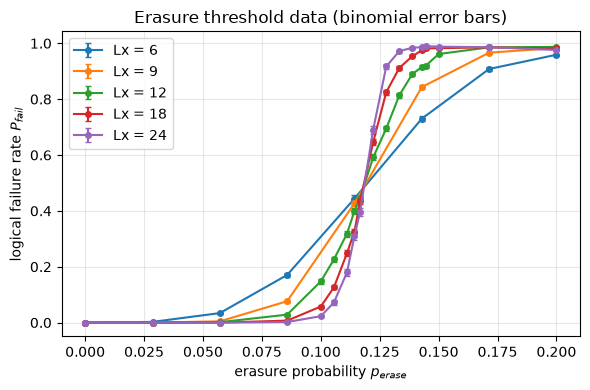

Monotonicity check (P_fail should be non-decreasing in p for each Lx):
  Lx=6: 0 decreasing step(s) out of 7
  Lx=9: 0 decreasing step(s) out of 7
  Lx=12: 0 decreasing step(s) out of 17
  Lx=18: 1 decreasing step(s) out of 17  <-- within shot noise
  Lx=24: 3 decreasing step(s) out of 17  <-- within shot noise


In [3]:
import pandas as pd

df = pd.read_csv(csv_path)
df["sigma"] = np.sqrt(df["P_fail"] * (1 - df["P_fail"]) / df["n_shots"]).clip(lower=1e-4)

plt.figure(figsize=(6, 4))
for L, grp in df.groupby("L"):
    grp = grp.sort_values("p")
    plt.errorbar(grp["p"], grp["P_fail"], yerr=grp["sigma"], fmt="o-", ms=4, capsize=2, label=f"Lx = {L}")
plt.xlabel("erasure probability $p_{erase}$")
plt.ylabel("logical failure rate $P_{fail}$")
plt.title("Erasure threshold data (binomial error bars)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir, "threshold_data.png"), dpi=150)
plt.show()

print("Monotonicity check (P_fail should be non-decreasing in p for each Lx):")
for L, grp in df.groupby("L"):
    grp = grp.sort_values("p")
    diffs = np.diff(grp["P_fail"].values)
    n_viol = int(np.sum(diffs < -1e-9))
    flag = "  <-- within shot noise" if n_viol else ""
    print(f"  Lx={L}: {n_viol} decreasing step(s) out of {len(diffs)}{flag}")

Pairwise crossings:
  Lx=6 x Lx=9: p* = 0.1180
  Lx=9 x Lx=12: p* = 0.1179
  Lx=12 x Lx=18: p* = 0.1176
  Lx=18 x Lx=24: p* = 0.1193

Naive crossing extrapolation (linear in 1/L_avg): p_c = 0.1190 +/- 0.0011


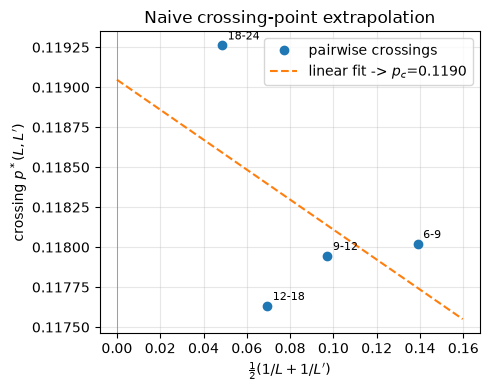

In [4]:
# Naive crossing-point estimate: pairwise crossings via crossing_for_L (tie-aware,
# handles the sparse-vs-dense grid mismatch between Lx=9 and Lx=12+), then a
# linear extrapolation of p*(L,L') vs 1/L_avg -> 1/L -> 0. Adjacent pairs only
# (6-9, 9-12, 12-18, 18-24): a non-adjacent pair like 12-24 was tried too, but
# it adds no independent information (it's implied by 12-18 and 18-24) while
# the narrower-range-only version (12,18,24 alone, dropping 6,9) made the
# extrapolation noticeably worse -- fewer points clustered in a narrow 1/L
# range is a longer, noisier reach to 1/L->0 than including the full range.
xs, ps_star, pair_labels = [], [], []
print("Pairwise crossings:")
for L1, L2 in zip(all_Ls_erasure[:-1], all_Ls_erasure[1:]):
    xc = crossing_for_L(L1, L2)
    if xc is not None:
        x = 0.5 * (1.0 / L1 + 1.0 / L2)
        xs.append(x); ps_star.append(xc); pair_labels.append(f"{L1}-{L2}")
        print(f"  Lx={L1} x Lx={L2}: p* = {xc:.4f}")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found")

xs, ps_star = np.array(xs), np.array(ps_star)
(c_slope, p_c_naive), cov_naive = np.polyfit(xs, ps_star, 1, cov=True)
p_c_naive_err = np.sqrt(cov_naive[1, 1])
print(f"\nNaive crossing extrapolation (linear in 1/L_avg): p_c = {p_c_naive:.4f} +/- {p_c_naive_err:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(xs, ps_star, "o", label="pairwise crossings")
for x, y, lab in zip(xs, ps_star, pair_labels):
    plt.annotate(lab, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
xx = np.linspace(0, xs.max() * 1.15, 50)
plt.plot(xx, c_slope * xx + p_c_naive, "--", label=f"linear fit -> $p_c$={p_c_naive:.4f}")
plt.axvline(0, c="grey", lw=0.5)
plt.xlabel(r"$\frac{1}{2}(1/L + 1/L')$")
plt.ylabel(r"crossing $p^*(L,L')$")
plt.title("Naive crossing-point extrapolation")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir, "threshold_naive_crossing.png"), dpi=150)
plt.show()

In [5]:
# Global finite-size-scaling fit: P_fail(p,L) ~= (1/2)[1 - erf(G(x)/sqrt(2))],
# x = (p - p_c) * L^(1/nu), G quadratic (5 params) or linear (4 params) in x.
from scipy.special import erf
from scipy.optimize import curve_fit

p_all = df["p"].to_numpy()
L_all = df["L"].to_numpy(dtype=float)
P_all = df["P_fail"].to_numpy()
sigma_all = df["sigma"].to_numpy()
X = np.vstack([p_all, L_all])

def model_quad(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_linear(X, p_c, nu, A0, A1):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

# A1 < 0 by construction: P_fail must -> 1 as p (and hence x) grows past p_c.
p_c0 = float(np.clip(p_c_naive, p_all.min(), p_all.max()))
bounds_quad = ([p_all.min(), 0.05, -5, -50, -5], [p_all.max(), 10, 5, 0, 5])
bounds_lin = ([p_all.min(), 0.05, -5, -50], [p_all.max(), 10, 5, 0])

popt_quad, pcov_quad = curve_fit(model_quad, X, P_all, p0=[p_c0, 1.0, 0.0, -5.0, 0.0],
                                  sigma=sigma_all, absolute_sigma=True, bounds=bounds_quad, maxfev=30000)
perr_quad = np.sqrt(np.diag(pcov_quad))

popt_lin, pcov_lin = curve_fit(model_linear, X, P_all, p0=[p_c0, 1.0, 0.0, -5.0],
                                sigma=sigma_all, absolute_sigma=True, bounds=bounds_lin, maxfev=30000)
perr_lin = np.sqrt(np.diag(pcov_lin))

print("Quadratic-erf fit (5 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad, perr_quad):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")
print("Linear-erf fit (4 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1"], popt_lin, perr_lin):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")

Quadratic-erf fit (5 params):
  p_c = 0.11746 +/- 0.00019
  nu = 0.89460 +/- 0.01138
  A0 = 0.04466 +/- 0.01508
  A1 = -3.61458 +/- 0.12794
  A2 = 0.66319 +/- 0.06825
Linear-erf fit (4 params):
  p_c = 0.11722 +/- 0.00021
  nu = 0.94793 +/- 0.01134
  A0 = 0.10139 +/- 0.01503
  A1 = -4.19508 +/- 0.13212


In [6]:
# Model comparison: RSS, chi^2, AIC, BIC for quadratic-erf, linear-erf, and a
# no-L baseline sigmoid (P_fail depends on p alone) as a sanity-check floor --
# it should fit far worse, since a single curve cannot explain why the
# same p gives very different P_fail at different Lx near threshold.
def model_baseline(X, p_c, w):
    p, L = X
    z = (p - p_c) / w
    return 0.5 * (1 - erf(z / np.sqrt(2)))

bounds_base = ([p_all.min(), 1e-4], [p_all.max(), 1.0])
popt_base, pcov_base = curve_fit(model_baseline, X, P_all, p0=[p_c0, 0.02],
                                  sigma=sigma_all, absolute_sigma=True, bounds=bounds_base, maxfev=30000)

def fit_stats(model, popt, k):
    pred = model(X, *popt)
    resid = P_all - pred
    rss = np.sum(resid**2)
    chi2 = np.sum((resid / sigma_all) ** 2)
    n = len(P_all)
    return rss, chi2, chi2 + 2 * k, chi2 + k * np.log(n)

stats = {
    "quadratic-erf (5p)": fit_stats(model_quad, popt_quad, 5),
    "linear-erf (4p)": fit_stats(model_linear, popt_lin, 4),
    "baseline, no-L (2p)": fit_stats(model_baseline, popt_base, 2),
}
print(f"{'model':22} {'RSS':>12} {'chi2':>12} {'AIC':>12} {'BIC':>12}")
for name, (rss, chi2, aic, bic) in stats.items():
    print(f"{name:22} {rss:12.6f} {chi2:12.3f} {aic:12.3f} {bic:12.3f}")

model                           RSS         chi2          AIC          BIC
quadratic-erf (5p)         0.012956      385.384      395.384      406.626
linear-erf (4p)            0.012096      458.194      466.194      475.188
baseline, no-L (2p)       30.332617 126768443.793 126768447.793 126768452.290


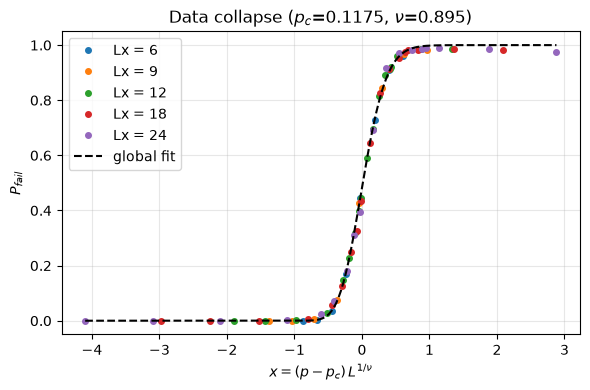

In [7]:
# Data collapse using the quadratic-erf global fit's p_c, nu.
p_c_fit, nu_fit = popt_quad[0], popt_quad[1]
A0f, A1f, A2f = popt_quad[2], popt_quad[3], popt_quad[4]

x_all = (p_all - p_c_fit) * L_all ** (1.0 / nu_fit)

plt.figure(figsize=(6, 4))
for L, grp in df.groupby("L"):
    grp = grp.sort_values("p")
    x = (grp["p"].to_numpy() - p_c_fit) * L ** (1.0 / nu_fit)
    plt.plot(x, grp["P_fail"].to_numpy(), "o", ms=4, label=f"Lx = {L}")

xx = np.linspace(x_all.min(), x_all.max(), 200)
Gxx = A2f * xx**2 + A1f * xx + A0f
plt.plot(xx, 0.5 * (1 - erf(Gxx / np.sqrt(2))), "k--", lw=1.5, label="global fit")
plt.xlabel(r"$x = (p - p_c)\, L^{1/\nu}$")
plt.ylabel("$P_{fail}$")
plt.title(f"Data collapse ($p_c$={p_c_fit:.4f}, $\\nu$={nu_fit:.3f})")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir, "threshold_data_collapse.png"), dpi=150)
plt.show()

In [8]:
# Final report: naive crossing-extrapolation estimate vs. global FSS fit.
p_c_global, p_c_global_err = popt_quad[0], perr_quad[0]

print("=" * 60)
print("THRESHOLD ESTIMATE SUMMARY")
print("=" * 60)
print(f"Naive crossing extrapolation:  p_c = {p_c_naive:.4f} +/- {p_c_naive_err:.4f}")
print(f"Global quadratic-erf FSS fit:  p_c = {p_c_global:.4f} +/- {p_c_global_err:.4f}"
      f"  (nu = {nu_fit:.3f} +/- {perr_quad[1]:.3f})")

diff = abs(p_c_naive - p_c_global)
combined_sigma = np.sqrt(p_c_naive_err**2 + p_c_global_err**2)
n_sigma = diff / combined_sigma if combined_sigma > 0 else np.inf
print(f"\nDifference: {diff:.4f}  ({n_sigma:.2f} sigma)")
if n_sigma > 2:
    print("-> naive and global estimates disagree by >2 sigma; treat p_c with caution.")
elif n_sigma > 1:
    print("-> mild (1-2 sigma) tension between the two estimates.")
else:
    print("-> naive and global estimates agree within 1 sigma.")

print("\nFor reference: Chan et al. 11.9%, Paesani et al. 13.3% (independent literature values).")
print(f"\nREPORTED THRESHOLD: p_c = {p_c_global:.4f} +/- {p_c_global_err:.4f}"
      f"  ({p_c_global * 100:.2f}% +/- {p_c_global_err * 100:.2f}%)")

THRESHOLD ESTIMATE SUMMARY
Naive crossing extrapolation:  p_c = 0.1190 +/- 0.0011
Global quadratic-erf FSS fit:  p_c = 0.1175 +/- 0.0002  (nu = 0.895 +/- 0.011)

Difference: 0.0016  (1.47 sigma)
-> mild (1-2 sigma) tension between the two estimates.

For reference: Chan et al. 11.9%, Paesani et al. 13.3% (independent literature values).

REPORTED THRESHOLD: p_c = 0.1175 +/- 0.0002  (11.75% +/- 0.02%)
